# A/B ExpLab AI
#### Autonomous A/B Experimentation Agentic Engine


A/B ExpLab AI transforms A/B testing from a manual, error-prone process into an automated statistically strong pipeline. Using a multi-agent system, ExpLab AI validates the integrity of the experiment, applies the appropriate statistical methods automatically, flags data quality risks in real-time, and translates complex results into actionable insights, while having a mandatory Human-in-the-Loop (HITL) safety net when data quality is compromised.


### Key Results

| Metric | Value |
|:---|:---|
| Dataset | Cookie Cats (90,189 users, mobile game A/B test) |
| Agents Used | 4 (Gatekeeper, Statistician, Narrator, Supervisor) |
| Statistical Methods | Chi-square, Welch's t-test, Mann-Whitney U, Bayesian Beta-Binomial |
| Multiple Testing Correction | Bonferroni + Benjamini-Hochberg (FDR) |
| HITL Accuracy | 100% (triggers correctly on SRM or invalid metric alignment) |
| Data Formats Supported | CSV, Parquet (10–100× faster), SQLite |
| Visualization | HTML bar charts saved as ADK Artifacts |
| Model | Gemini 2.5 Flash Lite using Google ADK |



### Steps to Execute This Notebook

1. Ensure `GEMINI_API_KEY` is set in your `.env` file
2. Place `cookie_cats.csv` in the working directory
3. Run each cell one by one. Click ▶️ button or press *Shift + Enter*
4. Key outputs to review:
   - **Gatekeeper Agent cell:** SRM check, metric alignment, sample size adequacy
   - **Statistician Agent cell:** Frequentist + Bayesian test results
   - **Narrator Agent cell:** Business recommendation + HTML chart artifact
   - **Main Execution cell:** Full standalone four-step analysis report



### Navigation

| Section | Description |
|:---|:---|
| Import Libraries | All dependencies and ADK imports |
| Configuration | API key loading and retry settings |
| Data Layer | Multi-format loader (CSV / Parquet / SQLite) |
| Gatekeeper Agent | SRM detection, metric alignment, sample size checks |
| Statistical Agent | Test selection, frequentist + Bayesian analysis, multiple testing correction |
| Narrator Agent | Business narrative, risk assessment, HTML chart artifact |
| Supervisor Agent | Orchestration and HITL checkpoint enforcement |
| App & Runner Setup | ADK App, session, memory, and logging configuration |
| Usage Example | Full async agentic pipeline (`run_complete_analysis`) |
| Cookie Cats Analysis | Standalone statistical report (`run_cookie_cats_analysis`) |
| ADK Web UI | Launching the interactive chat dashboard |
| Main Execution | Complete end-to-end run with feature summary |


### Architecture Overview

ExpLab AI uses a hierarchical multi-agent system with a Supervisor agent orchestrating three specialist sub-agents in a sequential, gate-keeping pipeline:

```
Supervisor Agent (explab_supervisor)
│
├─► Step 1: Gatekeeper Agent        ← Always runs first to ensure statistics are executed on good data
│   ├─► check_sample_ratio_mismatch      (SRM detection via Chi-square)
│   ├─► validate_metric_alignment         (metric appropriateness for test type)
│   └─► check_sample_size_adequacy        (power analysis — Z-factor method)
│
├─► Step 2: Statistician Agent      ← Runs only after Gatekeeper passes or after human approval
│   ├─► check_statistical_assumptions     (binary check, normality, CLT, skewness)
│   ├─► run_statistical_test              (Chi-square / Welch's t-test / Mann-Whitney U)
│   ├─► apply_multiple_testing_correction (Bonferroni + Benjamini-Hochberg FDR)
│   └─► run_bayesian_ab_test              (Beta-Binomial conjugate model)
│
└─► Step 3: Narrator Agent          ← Translates numbers into a business decision
    └─► generate_business_narrative       (verdict + risk assessment + HTML chart artifact)
```

**Principle of Design** 

The Gatekeeper always runs first. If it raises a `requires_human_approval` flag (SRM detected, wrong metric, or underpowered sample), the Supervisor pauses the pipeline and waits for human confirmation before any statistics are computed. This prevents wasted compute and misleading results from compromised data.



#### Agent Responsibilities

| Agent | Type | Key Function | Problem It Solves |
|:---|:---|:---|:---|
| Gatekeeper Agent | LlmAgent | Validates experiment integrity before analysis begins | Data quality failures (SRM, wrong metrics, low power) |
| Statistician Agent | LlmAgent | Selects and runs the correct test; applies multiple testing correction; runs Bayesian analysis | Wrong test selection, p-hacking, false discovery inflation |
| Narrator Agent | LlmAgent | Converts statistical output to a business decision with risk assessment and HTML chart | Communication gap between statistics and product decisions |
| Supervisor Agent | LlmAgent (Orchestrator) | Routes tasks between agents; enforces HITL checkpoint when validation fails | Unsafe automation proceeding on bad data |



#### Why This Architecture?

**Gate-keeping:** Running statistics on SRM-contaminated data produces results that appear precise but are unreliable. By making the Gatekeeper a strict requirement with a HITL pause when it fails, the pipeline prevents the most common source of invalid A/B test conclusions.

**Specialist agents over a monolith:** Each agent has a specific role and its own tool set. The Gatekeeper does not know about Bayesian analysis, the Statistician does not know about chart generation. This makes each agent's behaviour easier to analyze, test, and improve independently.

**Dual frequentist + Bayesian:** A p-value alone answers "is this effect non-zero?". It says nothing about how probable it is that the treatment is truly better, or how much is the risk losing if you ship it. The Bayesian Beta-Binomial model provides `P(treatment > control)` and an expected loss metric, giving product teams a fuller context for decision-making.


## Import Libraries

This cell imports all dependencies needed across the full pipeline

In [1]:
import os
import pandas as pd
import numpy as np
import sqlite3
import time
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from typing import Dict, Any, List, Optional, Tuple
from IPython.display import display, HTML

from google.adk.agents import LlmAgent
from google.adk.models.google_llm import Gemini
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.adk.memory import InMemoryMemoryService
from google.adk.tools import AgentTool, ToolContext
from google.adk.plugins.logging_plugin import LoggingPlugin
from google.adk.apps.app import App, ResumabilityConfig
from google.genai import types


## Configuration

API Key is loaded from a `.env` file using `python-dotenv`. Create a `.env` file in the project root with:
```
GEMINI_API_KEY=your_key_here
```
Get your key from: https://aistudio.google.com/apikey


In [2]:
from dotenv import load_dotenv, find_dotenv
_ = load_dotenv(find_dotenv('.env'))
GEMINI_API_KEY = os.environ['GEMINI_API_KEY']


Retry configuration is defined here and shared across all agents:
```python
retry_config = types.HttpRetryOptions(
    attempts=3, exp_base=2, initial_delay=5,
    http_status_codes=[429, 500, 503, 504]
)
```
This exponential backoff handles API rate limits (HTTP 429) and transient server errors which is critical for multi-agent pipelines that make several back-to-back API calls for each analysis run. Without it, a single transient failure would abort the entire workflow.

`SUPPORTED_FORMATS` defines the accepted data file types: `.parquet`, `.sqlite`, and `.csv`.

In [3]:
retry_config = types.HttpRetryOptions(
    attempts=3,
    exp_base=2,
    initial_delay=5,
    http_status_codes=[429, 500, 503, 504]
)

SUPPORTED_FORMATS = ['.parquet', '.sqlite', '.csv']


## Data Layer with Multi-Format Support

The data layer provides a single entry point i.e. `load_experiment_data` that handles three file formats and validates the dataset schema before any agent work begins.

**Why multi-format?**
- CSV is the most common export format but is slow for large datasets
- Parquet with Snappy compression loads 10–100× faster and is automatically generated from CSV when the dataset exceeds 10,000 rows. Therefore, subsequent runs benefit without any manual conversion step.
- SQLite supports teams with existing database pipelines, querying the `experiments` table directly

**Schema validation** is enforced before returning data, the four required columns (`userid`, `version`, `retention_1`, `retention_7`) must all be present. If any are missing, a structured error is returned rather than a Python exception so that agents can receive a parseable failure message rather than crashing.

A dictionary with status, data, summary, and performance metrics is returned.


In [4]:
def load_experiment_data(file_path: str = "cookie_cats.csv",
                         auto_convert: bool = True) -> Dict[str, Any]:
    try:
        path = Path(file_path)
        suffix = path.suffix.lower()
        start = time.time()

        if suffix == '.parquet':
            data = pd.read_parquet(file_path)
            format_used = "Parquet (optimized)"
        elif suffix in ['.db', '.sqlite', '.sqlite3']:
            conn = sqlite3.connect(file_path)
            data = pd.read_sql_query("SELECT * FROM experiments", conn)
            conn.close()
            format_used = 'SQLite'
        else:
            data = pd.read_csv(file_path)
            format_used = "CSV"
            if auto_convert and len(data) > 10000:
                parquet_path = path.with_suffix('.parquet')
                data.to_parquet(parquet_path, compression='snappy')
                format_used = f"CSV (converted to {parquet_path.name})"

        load_time = time.time() - start

        required_cols = ['userid', 'version', 'retention_1', 'retention_7']
        if not all(col in data.columns for col in required_cols):
            return {
                "status": "error",
                "error_message": f"Missing columns. Expected: {required_cols}, Found: {list(data.columns)}"
            }

        summary = {
            "total_users": len(data),
            "format": format_used,
            "load_time_ms": round(load_time * 1000, 2),
            "control_group": {
                "size": len(data[data.version == 'gate_30']),
                "retention_1": float(data[data.version == 'gate_30'].retention_1.mean()),
                "retention_7": float(data[data.version == 'gate_30'].retention_7.mean())
            },
            "treatment_group": {
                "size": len(data[data.version == 'gate_40']),
                "retention_1": float(data[data.version == 'gate_40'].retention_1.mean()),
                "retention_7": float(data[data.version == 'gate_40'].retention_7.mean())
            }
        }

        return {"status": "success", "data": data, "summary": summary}

    except FileNotFoundError:
        return {
            "status": "error",
            "error_message": f"Dataset not found: {file_path}. Supported formats: {SUPPORTED_FORMATS}"
        }
    except Exception as e:
        return {"status": "error", "error_message": f"Error loading data: {str(e)}"}


## Gatekeeper Agent

The Gatekeeper is the first agent in the pipeline and acts as a hard quality gate. No statistical analysis runs until the Gatekeeper passes. It executes three checks in order, each of which can independently trigger a Human-in-the-Loop pause:

| Check | Tool | Triggers HITL when... |
|:---|:---|:---|
| Sample Ratio Mismatch | `check_sample_ratio_mismatch` | Split deviates > 2% from 50/50 AND Chi-square p < 0.01 |
| Metric Alignment | `validate_metric_alignment` | Chosen metric is inappropriate for the test type |
| Sample Size Adequacy | `check_sample_size_adequacy` | Current N is below the required N for 80% power at 2% MDE |

**Why check SRM first?** 

SRM is the most critical failure. If randomization is broken, all downstream statistics are invalid regardless of sample size or metric choice. Detecting it before running any analysis saves compute and prevents presenting incorrect, unreliable results.

**HITL behaviour** 

If any check sets `requires_human_approval: True`, the Supervisor brings up a `⏸️ HUMAN APPROVAL REQUIRED` message and pauses. The pipeline cannot resume until the user responds with `APPROVED` or `REJECT`. This is enforced by `ResumabilityConfig(is_resumable=True)` in the App setup.


The function `validate_metric_alignment` validates if the chosen metric is appropriate for the test type.

For Cookie Cats gate placement test:
- Appropriate metrics: retention_1, retention_7 (binary outcomes)
- Inappropriate metrics: sum_gamerounds (count metric, not retention)

Returns dictionary with validation result and suggestions.


In [5]:
def validate_metric_alignment(
    test_type: str,
    metric: str
) -> Dict[str, Any]:
    valid_metrics = {
        "gate_placement": ["retention_1", "retention_7"],
        "feature_test":   ["retention_1", "retention_7", "sum_gamerounds"],
        "ui_change":      ["retention_1", "click_rate"],
        "onboarding_flow":["retention_1", "retention_7", "session_length"]
    }

    if test_type in valid_metrics:
        is_valid = metric in valid_metrics[test_type]
        if is_valid:
            return {
                "status": "success",
                "valid": True,
                "message": f"{metric} is appropriate for {test_type} test"
            }
        return {
            "status": "success",
            "valid": False,
            "message": f"{metric} is NOT recommended for {test_type}",
            "suggestions": valid_metrics[test_type],
            "requires_human_approval": True
        }

    return {
        "status": "success",
        "valid": True,
        "message": "No specific validation rules for this test type"
    }


The function `check_sample_ratio_mismatch` detects Sample Ratio Mismatch (SRM).

SRM occurs when the actual split differs from expected (e.g., 45/55 instead of 50/50).
Industry standard: Flag if deviation > 2% from expected split.


In [6]:
def check_sample_ratio_mismatch(
    file_path: str = "cookie_cats.csv",
    expected_ratio: float = 0.5,
    tolerance: float = 0.02
) -> Dict[str, Any]:
    try:
        data = pd.read_csv(file_path)
        total          = len(data)
        control_size   = len(data[data.version == 'gate_30'])
        treatment_size = len(data[data.version == 'gate_40'])
        actual_ratio   = treatment_size / total
        deviation      = abs(actual_ratio - expected_ratio)

        expected_counts = [total * (1 - expected_ratio), total * expected_ratio]
        observed_counts = [control_size, treatment_size]
        chi2, p_value   = stats.chisquare(observed_counts, expected_counts)

        has_srm = (deviation > tolerance) and (p_value < 0.01)

        if has_srm:
            severity              = "CRITICAL" if deviation > 0.05 else "WARNING"
            message               = f"SRM DETECTED: {actual_ratio:.1%} treatment (expected {expected_ratio:.1%})"
            recommendation        = "STOP TEST - Investigate randomization before analyzing results"
            requires_human_approval = True
        else:
            severity              = "OK"
            message               = f"No SRM: {actual_ratio:.1%} treatment (within {tolerance:.1%} tolerance)"
            recommendation        = "Safe to proceed with analysis"
            requires_human_approval = False

        return {
            "status": "success",
            "has_srm": has_srm,
            "severity": severity,
            "actual_ratio": actual_ratio,
            "expected_ratio": expected_ratio,
            "deviation": deviation,
            "chi2_p_value": p_value,
            "control_size": control_size,
            "treatment_size": treatment_size,
            "message": message,
            "recommendation": recommendation,
            "requires_human_approval": requires_human_approval
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


The function `check_sample_size_adequacy` checks if sample size is adequate for detecting meaningful effects.

Uses power analysis (Z-factor method) to verify we have enough users to detect a given lift.


In [7]:
def check_sample_size_adequacy(
    file_path: str = "cookie_cats.csv",
    metric: str = "retention_7",
    min_detectable_effect: float = 0.02
) -> Dict[str, Any]:
    try:
        data     = pd.read_csv(file_path)
        control  = data[data.version == 'gate_30'][metric]
        n        = len(control)
        is_binary = set(control.dropna().unique()).issubset({0, 1, True, False})

        # Z-factor for 80% power + 5% alpha → (1.96 + 0.84)^2 ≈ 7.84
        z_factor = 7.84
        variance = control.mean() * (1 - control.mean()) if is_binary else control.var()
        required_n = int((2 * z_factor * variance) / (min_detectable_effect ** 2))
        is_adequate = n >= required_n

        return {
            "status": "success",
            "adequate": is_adequate,
            "current_n": n,
            "required_n": required_n,
            "message": f"{'✓' if is_adequate else '⚠️'} Sample size: {n:,} users ({'sufficient' if is_adequate else 'underpowered'})",
            "requires_human_approval": not is_adequate
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


### Gatekeeper Agent Definition

The `gatekeeper_agent` is an `LlmAgent` configured with:
- `temperature=0.0` - deterministic output; validation decisions should never vary between runs
- `max_output_tokens=512` - validation output is concise by design
- `output_key="gatekeeper_output"` - stores results in session state so the Supervisor and downstream agents can reference the validation findings

Its instruction enforces a strict checklist order: SRM → metric alignment → sample size. If SRM is detected, the agent outputs an immediate halt message without proceeding to the other checks.


In [8]:
gatekeeper_agent = LlmAgent(
    model=Gemini(
        model="gemini-2.5-flash-lite",
        retry_options=retry_config,
        generate_content_config=types.GenerateContentConfig(max_output_tokens=512, temperature=0.0)
    ),
    name="gatekeeper_agent",
    description="Validates experiment design with SRM detection before analysis",
    instruction="""
    You are an experimentation design expert for mobile game A/B tests.

    VALIDATION CHECKLIST (Run ALL checks):

    1. Sample Ratio Mismatch (SRM) — CRITICAL FIRST CHECK
       - Use check_sample_ratio_mismatch tool
       - If SRM detected: STOP immediately, flag for human review

    2. Metric Alignment
       - Use validate_metric_alignment tool
       - retention_1/retention_7 → Good for gate placement tests
       - sum_gamerounds → Not ideal for retention tests

    3. Sample Size Adequacy
       - Use check_sample_size_adequacy tool
       - Need ~4000 users per group for 2% lift detection

    OUTPUT FORMAT:
    If ALL checks pass:
        "✓ VALIDATION PASSED
         - No SRM detected
         - Metric appropriate
         - Sample size adequate
         → PROCEED to statistical analysis"

    If ANY check fails:
        "⚠️ VALIDATION FAILED
         Issues found: [list problems]
         REQUIRES HUMAN APPROVAL before proceeding"
    """,
    tools=[check_sample_ratio_mismatch, validate_metric_alignment, check_sample_size_adequacy],
    output_key="gatekeeper_output"
)


## Statistical Agent

The Statistician Agent runs after the Gatekeeper confirms the experiment is valid. It is responsible for selecting the correct test, executing it, correcting for multiple comparisons, and running a complementary Bayesian analysis.

**Why not just always use a t-test?**  
The t-test assumes approximately normal data. Retention metrics (`retention_1`, `retention_7`) are binary, a player either returned or didn't return. Applying a t-test to binary data is technically wrong and can produce misleading effect size estimates. The assumption-checking step makes test selection automatic and defensible.

**Why Bayesian in addition to frequentist?**  
A p-value answers *"If there were no effect, how surprising is this data?"*. It does not answer *"How likely is it that the treatment is genuinely better?"* The Bayesian Beta-Binomial model directly answers the second question, and also provides an expected loss metric, the average retention you lose if you ship the treatment and the control was actually better. This is a more decision-relevant risk measure for product teams.


The function `check_statistical_assumptions` checks for normality and variance assumptions.

In [9]:
def check_statistical_assumptions(
    file_path: str = "cookie_cats.csv",
    metric: str = "retention_7"
) -> Dict[str, Any]:
    try:
        data      = pd.read_csv(file_path)
        control   = data[data.version == 'gate_30'][metric]
        treatment = data[data.version == 'gate_40'][metric]
        is_binary = set(control.dropna().unique()).issubset({0, 1, True, False})

        if is_binary:
            return {
                "status": "success",
                "test_recommendation": "chi_square",
                "reason": "Binary outcome (retention) — use Chi-square test",
                "normality": "Not applicable for binary data"
            }

        n_control = len(control)

        if n_control >= 1000:
            skewness = abs(control.skew())
            if skewness > 3.0:
                test_rec = "mann_whitney"
                reason   = f"Large sample (N={n_control}) but highly skewed (skew={skewness:.2f}) — use Mann-Whitney"
            else:
                test_rec = "t_test"
                reason   = f"Large sample (N={n_control}), CLT applies (skew={skewness:.2f}) — use Welch's t-test"
            return {
                "status": "success",
                "test_recommendation": test_rec,
                "reason": reason,
                "normality": "Bypassed Shapiro-Wilk — CLT applies for large samples"
            }

        _, p_control   = stats.shapiro(control)
        _, p_treatment = stats.shapiro(treatment)
        is_normal      = (p_control > 0.05) and (p_treatment > 0.05)

        return {
            "status": "success",
            "test_recommendation": "t_test" if is_normal else "mann_whitney",
            "reason": f"Data is {'normal' if is_normal else 'non-normal'}",
            "normality": f"p-values: control={p_control:.3f}, treatment={p_treatment:.3f}"
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


The function `run_statistical_test` runs the appropriate statistical test based on data type.

In [10]:
def run_statistical_test(
    file_path: str = "cookie_cats.csv",
    metric: str = "retention_7",
    test_type: str = "auto"
) -> Dict[str, Any]:
    try:
        data      = pd.read_csv(file_path)
        control   = data[data.version == 'gate_30'][metric]
        treatment = data[data.version == 'gate_40'][metric]

        if test_type == "auto":
            is_binary = set(control.unique()).issubset({0, 1, True, False})
            test_type = "chi_square" if is_binary else "t_test"

        if test_type == "chi_square":
            contingency       = pd.crosstab(data['version'], data[metric])
            chi2, p_value, dof, _ = stats.chi2_contingency(contingency)
            effect_size       = float(treatment.mean() - control.mean())
            se = np.sqrt(
                control.mean() * (1 - control.mean()) / len(control) +
                treatment.mean() * (1 - treatment.mean()) / len(treatment)
            )
            result = {
                "test_used": "Chi-square test",
                "statistic": float(chi2),
                "p_value": float(p_value),
                "effect_size": effect_size,
                "confidence_interval_95": (round(effect_size - 1.96 * se, 4), round(effect_size + 1.96 * se, 4)),
                "control_rate": float(control.mean()),
                "treatment_rate": float(treatment.mean())
            }

        elif test_type == "mann_whitney":
            statistic, p_value = stats.mannwhitneyu(control, treatment)
            effect_size        = (treatment.mean() - control.mean()) / control.std()
            rng   = np.random.default_rng(42)
            diffs = [
                rng.choice(treatment.values, size=len(treatment), replace=True).mean() -
                rng.choice(control.values,   size=len(control),   replace=True).mean()
                for _ in range(1000)
            ]
            ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
            result = {
                "test_used": "Mann-Whitney U test",
                "statistic": float(statistic),
                "p_value": float(p_value),
                "effect_size": float(effect_size),
                "confidence_interval_95": (round(ci_lower, 4), round(ci_upper, 4))
            }

        else:  # t-test
            statistic, p_value = stats.ttest_ind(control, treatment)
            effect_size        = (treatment.mean() - control.mean()) / control.std()
            diff = treatment.mean() - control.mean()
            se   = np.sqrt(control.var() / len(control) + treatment.var() / len(treatment))
            result = {
                "test_used": "Independent t-test",
                "statistic": float(statistic),
                "p_value": float(p_value),
                "effect_size": float(effect_size),
                "confidence_interval_95": (round(diff - 1.96 * se, 4), round(diff + 1.96 * se, 4))
            }

        result["status"]      = "success"
        result["significant"] = bool(p_value < 0.05)
        result["conclusion"]  = "Significant difference detected" if result["significant"] else "No significant difference"
        return result

    except Exception as e:
        return {"status": "error", "error_message": str(e)}


The function `apply_multiple_testing_correction` prevents false positives when testing several metrics simultaneously.

Methods: 'bonferroni' (conservative), 'fdr_bh' (Benjamini-Hochberg, less conservative).


In [11]:
def apply_multiple_testing_correction(
    p_values: List[float],
    metric_names: List[str],
    method: str = "bonferroni"
) -> Dict[str, Any]:
    try:
        reject, p_corrected, _, _ = multipletests(p_values, method=method)
        results = [
            {
                "metric": name,
                "original_p_value": round(float(orig_p), 4),
                "corrected_p_value": round(float(corr_p), 4),
                "significant_after_correction": bool(rej)
            }
            for name, orig_p, corr_p, rej in zip(metric_names, p_values, p_corrected, reject)
        ]
        return {
            "status": "success",
            "method": method,
            "n_tests": len(p_values),
            "results": results,
            "warning": f"With {len(p_values)} simultaneous tests, uncorrected alpha inflates Type I error rate."
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


The function `run_bayesian_ab_test` runs a Bayesian A/B test using a Beta-Binomial conjugate model.

Returns probability that treatment beats control, expected lift, and 95% credible interval.
Only valid for binary metrics (e.g. retention_1, retention_7).


In [12]:
def run_bayesian_ab_test(
    file_path: str = "cookie_cats.csv",
    metric: str = "retention_7",
    n_samples: int = 100_000
) -> Dict[str, Any]:
    try:
        data      = pd.read_csv(file_path)
        control   = data[data.version == 'gate_30'][metric]
        treatment = data[data.version == 'gate_40'][metric]

        if not set(control.unique()).issubset({0, 1, True, False}):
            return {"status": "error", "error_message": "Bayesian Beta-Binomial model only applies to binary metrics."}

        # Uniform Beta(1,1) prior
        alpha_control   = 1 + int(control.sum())
        beta_control    = 1 + int(len(control) - control.sum())
        alpha_treatment = 1 + int(treatment.sum())
        beta_treatment  = 1 + int(len(treatment) - treatment.sum())

        rng               = np.random.default_rng(42)
        control_samples   = rng.beta(alpha_control,   beta_control,   n_samples)
        treatment_samples = rng.beta(alpha_treatment, beta_treatment, n_samples)
        diff_samples      = treatment_samples - control_samples

        prob_treatment_better   = float((diff_samples > 0).mean())
        expected_lift           = float(diff_samples.mean())
        ci_lower, ci_upper      = np.percentile(diff_samples, [2.5, 97.5])
        expected_loss_treatment = float(np.maximum(control_samples - treatment_samples, 0).mean())

        return {
            "status": "success",
            "model": "Beta-Binomial (conjugate)",
            "prob_treatment_better": round(prob_treatment_better, 4),
            "prob_control_better":   round(1 - prob_treatment_better, 4),
            "expected_lift":         round(expected_lift, 4),
            "credible_interval_95":  (round(float(ci_lower), 4), round(float(ci_upper), 4)),
            "expected_loss_if_ship_treatment": round(expected_loss_treatment, 4),
            "posterior_control":   {"mean": round(alpha_control   / (alpha_control   + beta_control),   4), "alpha": alpha_control,   "beta": beta_control},
            "posterior_treatment": {"mean": round(alpha_treatment / (alpha_treatment + beta_treatment), 4), "alpha": alpha_treatment, "beta": beta_treatment},
            # FIX: 'interpretation' key restored — was missing, caused KeyError in run_cookie_cats_analysis
            "interpretation": (
                f"There is a {prob_treatment_better:.1%} probability that gate_40 outperforms gate_30 "
                f"on {metric}. Expected lift: {expected_lift:+.4f} "
                f"(95% CI: {ci_lower:+.4f} to {ci_upper:+.4f})."
            )
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


### Statistician Agent Definition

The `statistician_agent` is an `LlmAgent` with a structured four-step workflow instruction: check assumptions → run the recommended frequentist test → apply multiple testing correction if multiple metrics are tested → run Bayesian analysis for binary metrics.

- `temperature=0.0` - statistical interpretation should be reproducible
- `max_output_tokens=512` - structured output covering test name, p-value, corrected p-value, effect size, 95% CI, and Bayesian probability
- `output_key="statistician_output"` - results stored in session state for the Narrator to consume


In [13]:
statistician_agent = LlmAgent(
    model=Gemini(
        model="gemini-2.5-flash-lite",
        retry_options=retry_config,
        generate_content_config=types.GenerateContentConfig(max_output_tokens=512, temperature=0.0)
    ),
    name="statistician_agent",
    description="Performs rigorous statistical analysis with assumption checking, CI, multiple testing correction, and Bayesian testing",
    instruction="""
    You are a statistical expert for A/B test analysis.

    WORKFLOW:
    1. Check assumptions using check_statistical_assumptions
    2. Run the appropriate frequentist test using run_statistical_test
    3. If multiple metrics are tested simultaneously, run apply_multiple_testing_correction
    4. For binary metrics (retention_1, retention_7), also run run_bayesian_ab_test

    OUTPUT FORMAT:
    Test: [Chi-square / t-test / Mann-Whitney]
    P-value: [value]  |  Corrected P-value: [value] (method)
    Effect Size: [value]
    95% Confidence Interval: [lower, upper]
    Conclusion: [Significant / Not significant]

    Bayesian Analysis:
    P(treatment > control): [value]
    Expected Lift: [value]  |  95% Credible Interval: [lower, upper]
    """,
    tools=[
        check_statistical_assumptions,
        run_statistical_test,
        apply_multiple_testing_correction,
        run_bayesian_ab_test
    ],
    output_key="statistician_output"
)


## Narrator Agent

The Narrator Agent is the final analytical step. It takes statistical outputs and validation context from the previous two agents and produces a business decision with a structured risk assessment in a language a product manager or executive can act on directly.

**The translation problem** 

Statistical significance (p < 0.05) and business significance are not the same thing. A 0.1% lift in retention might be statistically significant at 90,000 users but have negligible business impact. Conversely, a borderline p-value combined with a Bayesian posterior of 95% that the treatment is better is very actionable. The Narrator generates all of this into a single clear verdict.

**Risk tiers surfaced in every report:**

| Risk Level | Condition | Meaning |
|:---|:---|:---|
| `CRITICAL` | SRM detected | Test results are unreliable. Do not ship based on this analysis |
| `WARNING` | Underpowered sample | Real differences may be missed (Type II error risk) |
| `INFO` | Lift < 1% despite significance | Statistically real but practically negligible effect |

**ADK Artifact:** The HTML bar chart is saved via `tool_context.save_artifact()` as a `text/html` artifact. In the ADK Web UI (`adk web`), this renders as an interactive report in the Artifacts tab, ready to screenshot for stakeholder presentations.


The function `generate_business_narrative` converts statistical results to business language with Risk section.
Includes an HTML bar chart as an ADK Artifact to render in the Artifacts tab.


In [ ]:
def generate_business_narrative(
    p_value: float,
    effect_size: float,
    significant: bool,
    control_rate: float,
    treatment_rate: float,
    metric_name: str,
    tool_context: ToolContext,
    has_srm: bool = False,
    sample_size_adequate: bool = True,
    daily_active_users: int = 10000
) -> dict:

    from google.adk.tools.tool_context import ToolContext
    from google.genai import types as genai_types

    try:
        lift_pct     = (effect_size / control_rate * 100) if control_rate > 0 else effect_size * 100
        impact_users = int(daily_active_users * abs(effect_size))

        if has_srm:
            recommendation = "DO NOT SHIP - DATA QUALITY ISSUE"
            reasoning      = "Sample Ratio Mismatch detected. Test is compromised"
        elif significant and effect_size > 0:
            recommendation = "SHIP IT"
            reasoning      = f"Strong positive impact on {metric_name} (+{lift_pct:.1f}%)"
        elif significant and effect_size < 0:
            recommendation = "DO NOT SHIP"
            reasoning      = f"Negative impact on {metric_name} ({lift_pct:.1f}%)"
        else:
            recommendation = "INCONCLUSIVE"
            reasoning      = "No statistically significant difference detected"

        risk_factors = []
        if has_srm:
            risk_factors.append({"type": "CRITICAL", "issue": "Sample Ratio Mismatch",
                                  "impact": "Test results are unreliable"})
        if not sample_size_adequate:
            risk_factors.append({"type": "WARNING", "issue": "Underpowered Test",
                                  "impact": "May miss real differences (Type II error risk)"})
        if abs(lift_pct) < 1 and significant:
            risk_factors.append({"type": "INFO", "issue": "Small Practical Effect",
                                  "impact": f"Lift is only {abs(lift_pct):.2f}%"})

        ctrl_pct  = round(control_rate * 100, 2)
        trt_pct   = round(treatment_rate * 100, 2)
        max_val   = max(ctrl_pct, trt_pct, 1)
        ctrl_h    = max(int(ctrl_pct / max_val * 160), 20)
        trt_h     = max(int(trt_pct  / max_val * 160), 20)
        badge_clr = {"SHIP IT": "#27ae60", "DO NOT SHIP": "#c0392b",
                     "INCONCLUSIVE": "#f39c12"}.get(recommendation, "#8e44ad")
        trt_bar_clr = "#2ecc71" if effect_size > 0 else "#e74c3c"
        risk_html = "".join(
            f"<li><b style='color:{"#c0392b" if r["type"]=="CRITICAL" else "#f39c12" if r["type"]=="WARNING" else "#2980b9"}'>"
            f"{r['type']}</b>: {r['issue']} — {r['impact']}</li>"
            for r in risk_factors
        ) if risk_factors else "<li style='color:#27ae60'>No significant risk factors ✓</li>"

        html = f"""<!DOCTYPE html>
<html>
<head><meta charset="utf-8">
<style>
  body {{ font-family: Arial, sans-serif; background: #1a1a2e; color: #eee; padding: 24px; margin: 0; }}
  .card {{ background: #16213e; border-radius: 12px; padding: 24px; max-width: 640px; margin: auto; box-shadow: 0 4px 24px #0004; }}
  h2 {{ margin-top: 0; color: #a8d8ea; }}
  .badge {{ display: inline-block; padding: 10px 22px; border-radius: 8px; font-size: 18px; font-weight: bold;
            background: {badge_clr}; color: white; margin-bottom: 20px; }}
  .bars {{ display: flex; gap: 32px; align-items: flex-end; height: 180px; margin: 24px 0 8px; }}
  .bar-wrap {{ flex: 1; text-align: center; }}
  .bar {{ border-radius: 6px 6px 0 0; display: flex; align-items: flex-end; justify-content: center;
          color: white; font-weight: bold; font-size: 15px; padding-bottom: 6px; }}
  .bar-label {{ margin-top: 8px; font-size: 13px; color: #aaa; }}
  .stats {{ background: #0f3460; border-radius: 8px; padding: 14px 18px; font-size: 14px; margin-top: 16px; line-height: 1.8; }}
  .risk {{ margin-top: 16px; font-size: 13px; }}
  ul {{ margin: 6px 0; padding-left: 20px; line-height: 1.8; }}
</style>
</head>
<body>
<div class="card">
  <h2>📊 {metric_name} — A/B Test Report</h2>
  <div class="badge">{recommendation}</div>

  <div class="bars">
    <div class="bar-wrap">
      <div class="bar" style="background:#3498db;height:{ctrl_h}px">{ctrl_pct}%</div>
      <div class="bar-label">Gate 30<br>(Control)</div>
    </div>
    <div class="bar-wrap">
      <div class="bar" style="background:{trt_bar_clr};height:{trt_h}px">{trt_pct}%</div>
      <div class="bar-label">Gate 40<br>(Treatment)</div>
    </div>
  </div>

  <div class="stats">
    <b>p-value:</b> {round(p_value, 4)} &nbsp;|&nbsp;
    <b>Lift:</b> <span style="color:{"#2ecc71" if lift_pct > 0 else "#e74c3c"}">{lift_pct:+.2f}%</span> &nbsp;|&nbsp;
    <b>{"✓ Significant" if significant else "✗ Not significant"}</b><br>
    <b>Effect size:</b> {effect_size:+.4f} &nbsp;|&nbsp;
    <b>Daily impact:</b> ~{impact_users:,} users/day
  </div>

  <div class="risk">
    <b>Risk Assessment:</b>
    <ul>{risk_html}</ul>
    <b>Verdict:</b>
    <span style="color:{"#27ae60" if not has_srm and significant else "#f39c12"}">
      {"SAFE TO SHIP" if (not has_srm and significant and effect_size > 0) else "DO NOT SHIP" if (significant and effect_size < 0) else "REQUIRES REVIEW"}
    </span>
  </div>
</div>
</body></html>"""

        # Save as ADK Artifact (renders in Artifacts tab)
        artifact_filename = f"{metric_name}_report.html"
        try:
            import asyncio
            from google.genai import types as genai_types

            artifact = genai_types.Part(
                inline_data=genai_types.Blob(
                    mime_type="text/html",
                    data=html.encode("utf-8")
                )
            )
            # save_artifact is async, run it in the current event loop
            loop = asyncio.get_event_loop()
            if loop.is_running():
                # Running inside async context (ADK web), schedule as coroutine
                import concurrent.futures
                future = asyncio.ensure_future(
                    tool_context.save_artifact(artifact_filename, artifact)
                )
            else:
                loop.run_until_complete(
                    tool_context.save_artifact(artifact_filename, artifact)
                )
            artifact_saved = True
        except Exception as ae:
            artifact_saved = False
            artifact_error = str(ae)

        return {
            "status":          "success",
            "recommendation":  recommendation,
            "reasoning":       reasoning,
            "lift_pct":        round(lift_pct, 2),
            "risk_level":      "CRITICAL" if has_srm else ("MEDIUM" if risk_factors else "LOW"),
            "overall_verdict": "SAFE TO SHIP" if (not has_srm and significant and effect_size > 0) else "DO NOT SHIP" if (significant and effect_size < 0) else "REQUIRES REVIEW",
            "artifact_file":   artifact_filename if artifact_saved else "not saved",
            "html_chart":      html,
            "summary": (
                f"{recommendation}: {metric_name} shows {lift_pct:+.2f}% lift "
                f"(p={round(p_value,4)}, {'significant' if significant else 'not significant'}). "
                f"Chart saved to artifact: {artifact_filename}. {reasoning}."
            )
        }
    except Exception as e:
        return {"status": "error", "error_message": str(e)}


In [15]:
narrator_agent = LlmAgent(
    model=Gemini(
        model="gemini-2.5-flash-lite",
        retry_options=retry_config,
        generate_content_config=types.GenerateContentConfig(max_output_tokens=2048, temperature=0.0)
    ),
    name="narrator_agent",
    description="Translates statistics into business language, saves HTML chart as ADK Artifact",
    instruction="""
    You translate A/B test statistics into an executive business report.

    Call generate_business_narrative with these flat arguments extracted from
    the statistician and gatekeeper outputs:
      - p_value              (float) from statistician
      - effect_size          (float) from statistician
      - significant          (bool)  from statistician
      - control_rate         (float) from statistician chi-square results
      - treatment_rate       (float) from statistician chi-square results
      - metric_name          (str)   e.g. "retention_7"
      - has_srm              (bool)  from gatekeeper, default False
      - sample_size_adequate (bool)  from gatekeeper, default True

    After calling the tool:
    1. State the recommendation clearly (SHIP IT / DO NOT SHIP / INCONCLUSIVE)
    2. Report the lift_pct, p-value, and risk_level from the tool result
    3. Tell the user: "The full HTML chart has been saved as an artifact.
       Click the Artifacts tab above to view the interactive chart."
    4. Include the summary field verbatim in your response
    """,
    tools=[generate_business_narrative]
)


## Supervisor Agent & Human-in-the-Loop (HITL)

The Supervisor is the root orchestrator. It does not do analysis itself. Instead, it coordinates the three specialist agents in order and enforces the most important rule in the pipeline - **the Gatekeeper cannot be skipped.**

### HITL Workflow

```
Supervisor receives analysis request
        │
        ▼
  [1] Call Gatekeeper Agent
        │
        ├── All checks pass ──────────────────────► [2] Call Statistician Agent
        │                                                       │
        └── Any check fails (requires_human_approval=True)      ▼
                    │                                   [3] Call Narrator Agent
                    ▼                                           │
          ⏸️ PIPELINE PAUSED                                    ▼
          "HUMAN APPROVAL REQUIRED"                    Final business report
          [list issues clearly]
                    │
          ┌─────────┴──────────┐
          ▼                    ▼
       APPROVED             REJECTED
          │                    │
          ▼                    ▼
  Resume at Step 2          STOP — analysis
                            does not proceed
```

### Why Is HITL Structurally Enforced?

The Supervisor's instruction contains the rule `CRITICAL: Never skip validation. Always check for requires_human_approval flag.` but the structural enforcement comes from `ResumabilityConfig(is_resumable=True)` in the App setup. This tells the ADK framework to preserve full session state when the workflow pauses, so:

- The pipeline resumes from exactly where it stopped after human approval
- No data is recomputed or lost during the pause
- The pause can last seconds in a notebook demo or hours in a production deployment



The helper function `prepare_narrator_inputs` packages the Gatekeeper's and Statistician's outputs into the flat argument structure that `generate_business_narrative` expects. It lives at the Supervisor level because it bridges the handoff between the statistical and narrative phases ensuring the Narrator receives both the test results and the validation context (SRM flag, sample size adequacy) needed for accurate risk assessment.

In [16]:
def prepare_narrator_inputs(
    p_value: float,
    effect_size: float,
    significant: bool,
    control_rate: float,
    treatment_rate: float,
    ci_lower: float,
    ci_upper: float,
    has_srm: bool,
    sample_size_adequate: bool,
    metric_name: str
) -> dict:
    """Formats statistician and gatekeeper outputs into the structure needed by generate_business_narrative."""
    return {
        "test_results": {
            "p_value": p_value,
            "effect_size": effect_size,
            "significant": significant,
            "control_rate": control_rate,
            "treatment_rate": treatment_rate,
            "confidence_interval_95": [ci_lower, ci_upper]
        },
        "validation_results": {
            "srm_check": {"has_srm": has_srm},
            "sample_size_check": {"adequate": sample_size_adequate}
        },
        "metric_name": metric_name
    }


In [17]:
supervisor_agent = LlmAgent(
    model=Gemini(
        model="gemini-2.5-flash-lite",
        retry_options=retry_config,
        generate_content_config=types.GenerateContentConfig(max_output_tokens=512, temperature=0.0)
    ),
    name="explab_supervisor",
    description="Orchestrates A/B test analysis with human-in-the-loop checkpoints",
    instruction="""
    You are the ExpLab AI supervisor managing A/B test analysis.

    WORKFLOW:
    1. VALIDATION — Delegate to gatekeeper_agent.
       If requires_human_approval == True:
         → PAUSE: "⏸️ HUMAN APPROVAL REQUIRED\n[list issues]\nReply APPROVED to continue or REJECT to stop."
         → Wait for user. APPROVED → Step 2. REJECT → STOP.

    2. STATISTICAL ANALYSIS — Delegate to statistician_agent.

    3. BUSINESS TRANSLATION — Delegate to narrator_agent.
       Pass BOTH test_results AND validation_results for risk assessment.

    CRITICAL RULES:
    - Never skip validation.
    - Always check for requires_human_approval flag.
    - If HITL triggered, STOP and wait for explicit user confirmation.
    """,
    tools=[
        AgentTool(agent=gatekeeper_agent),
        AgentTool(agent=statistician_agent),
        AgentTool(agent=narrator_agent),
        prepare_narrator_inputs
    ]
)


## App & Runner Setup

This section wires together the full ADK runtime stack.


The function `create_explab_app` wraps the `supervisor_agent` in an ADK `App` with two critical settings:

- `ResumabilityConfig(is_resumable=True)` enables the HITL pause/resume pattern. When the Supervisor pauses for human approval, the ADK framework serialises full session state. Execution resumes from the exact pause point after the user responds, with no data loss or recomputation.
- `LoggingPlugin()` captures every agent event, tool call, input, and output to the ADK logging system. This creates a complete, durable audit trail. Useful for debugging multi-agent handoffs and for reviewing why a particular statistical test was selected.

In [18]:
def create_explab_app():
    return App(
        name="explab_adk",
        root_agent=supervisor_agent,
        resumability_config=ResumabilityConfig(is_resumable=True),
        plugins=[LoggingPlugin()]
    )


The function `create_explab_runner` instantiates three services that together form the execution environment:

- `InMemorySessionService` manages per-conversation session state. Agent `output_key` values (e.g., `gatekeeper_output`, `statistician_output`) are stored here and shared across agents within the same session.
- `InMemoryMemoryService` - long-term memory across sessions. After analysis completes, the session is committed to memory so patterns (e.g., which experiments have been run, which metrics were flagged) persist beyond a single conversation.
- `Runner`- the ADK execution engine that orchestrates message routing between the App, session service, and memory service. `runner.run_async` is the entry point for submitting queries.

In [19]:
def create_explab_runner():
    app = create_explab_app()
    session_service = InMemorySessionService()
    memory_service  = InMemoryMemoryService()
    runner = Runner(
        app=app,
        session_service=session_service,
        memory_service=memory_service
    )
    return app, runner, session_service, memory_service


The function `render_artifact_to_html` is a utility that converts an ADK artifact dictionary (`chart_type: "bar"`) into an HTML string for inline notebook rendering via `IPython.display.HTML`. Used in `run_cookie_cats_analysis` to show the retention comparison chart directly in cell output — without requiring the ADK Web UI.

In [20]:
def render_artifact_to_html(artifact: Dict[str, Any]) -> str:
    """Converts an ADK artifact dict to an HTML bar chart string."""
    if artifact.get('chart_type') != 'bar':
        return "<p>Unsupported chart type</p>"

    labels      = artifact['data']['labels']
    values      = artifact['data']['values']
    colors      = artifact['data']['colors']
    annotations = artifact['annotations']
    title       = artifact.get('title', 'Chart')

    bars = ""
    for label, value, color in zip(labels, values, colors):
        bar_height = max(int(value * 3), 30)
        bars += f"""
        <div style="flex:1;text-align:center;">
            <div style="background:{color};height:{bar_height}px;min-height:30px;
                        display:flex;align-items:center;justify-content:center;
                        color:white;font-weight:bold;border-radius:5px 5px 0 0;">
                {value}%
            </div>
            <div style="margin-top:8px;font-size:13px;">{label}</div>
        </div>"""

    return f"""
    <div style="font-family:Arial,sans-serif;padding:20px;max-width:560px;
                border:1px solid #ddd;border-radius:8px;margin:16px 0;">
        <h3 style="margin-top:0;">{title}</h3>
        <div style="display:flex;gap:20px;align-items:flex-end;height:160px;margin:20px 0;">
            {bars}
        </div>
        <div style="background:#f8f9fa;padding:12px;border-radius:5px;font-size:13px;">
            <strong>Statistical Details:</strong><br>
            • {annotations['p_value']}<br>
            • {annotations['effect_size']}<br>
            • {annotations['significance']}
        </div>
    </div>"""


## Usage Example 
#### Complete Async Workflow

`run_complete_analysis` is the primary entry point for the full agentic pipeline. It stitches together data loading, agent initialisation, session management, event streaming, and HITL handling in a single async function.

**Important steps inside the function:**
1. Loads and summarises the dataset
2. Initialises the full agent stack via `create_explab_runner()`
3. Creates a unique session (`experiment_<uuid>`) to isolate this analysis run
4. Submits the analysis query to the Supervisor and streams events asynchronously
5. Detects HITL pause signals (`⏸️` or `HUMAN APPROVAL REQUIRED`) in the event stream
6. In demo mode: auto-approves and resumes to show the complete pipeline; in production: waits for real user input
7. Commits the completed session to memory for persistence

**Note on HITL in notebook context:** The auto-approval in this demo is a presentation convenience. The underlying `ResumabilityConfig` and Supervisor instruction implement the genuine pause/resume pattern. Deploy via `adk web` or Vertex AI Agent Engine for real human approval workflows.


In [21]:
async def run_complete_analysis(
    file_path: str = "cookie_cats.csv",
    metric: str = "retention_7",
    user_id: str = "analyst_001",
    session_id: str = None
):
    import uuid

    print("ExpLab AI: Enhanced A/B Testing Engine")
    print(f"\n Loading data from {file_path}...")

    data_result = load_experiment_data(file_path)
    if data_result["status"] == "error":
        print(f"❌ Error: {data_result['error_message']}")
        return

    s = data_result['summary']
    print(f"✓ Loaded {s['total_users']:,} users")
    print(f"  Format: {s['format']}  |  Load time: {s['load_time_ms']} ms")
    print(f"  Control: {s['control_group']['size']:,}  |  Treatment: {s['treatment_group']['size']:,}")

    print("\n🔧 Initialising ExpLab AI agents...")
    app, runner, session_service, memory_service = create_explab_runner()

    if session_id is None:
        session_id = f"experiment_{uuid.uuid4().hex[:8]}"

    await session_service.create_session(
        app_name="explab_adk",
        user_id=user_id,
        session_id=session_id
    )
    print(f"✓ Session created: {session_id}")

    query = (
        f"Analyse the gate placement test (gate_30 vs gate_40) on {metric}. "
        f"Use file_path='{file_path}' for all tool calls."
    )
    print(f"\n💬 Query: {query}")
    print("\n" + "-" * 70)
    print("ANALYSIS RESULTS")
    print("-" * 70 + "\n")

    query_content       = types.Content(role="user", parts=[types.Part(text=query)])
    requires_approval   = False
    approval_message    = ""

    async for event in runner.run_async(
        user_id=user_id, session_id=session_id, new_message=query_content
    ):
        if event.content and event.content.parts:
            for part in event.content.parts:
                if hasattr(part, 'text') and part.text:
                    if "HUMAN APPROVAL REQUIRED" in part.text or "⏸️" in part.text:
                        requires_approval = True
                        approval_message  = part.text
                    if event.is_final_response():
                        print(part.text)

    if requires_approval:
        print("\n" + "-" * 70)
        print("⚠️  WORKFLOW PAUSED — HUMAN DECISION REQUIRED")
        print("-" * 70)
        print(approval_message)
        print("\nFor this demo: Auto-approving to show complete flow...")

        approval_content = types.Content(
            role="user", parts=[types.Part(text="APPROVED — Proceed with analysis")]
        )
        print("\n" + "-" * 70)
        print("RESUMING ANALYSIS AFTER APPROVAL")
        print("-" * 70 + "\n")

        async for event in runner.run_async(
            user_id=user_id, session_id=session_id, new_message=approval_content
        ):
            if event.is_final_response() and event.content and event.content.parts:
                for part in event.content.parts:
                    if hasattr(part, 'text') and part.text:
                        print(part.text)

    print("\n" + "-" * 70)
    print("✓ ANALYSIS COMPLETE")
    print("-" * 70)

    session = await session_service.get_session(
        app_name="explab_adk",
        user_id=user_id,
        session_id=session_id
    )
    await memory_service.add_session_to_memory(session)
    print(f"\n💾 Session saved to memory. ID: {session_id}")


## Cookie Cats Analysis 
#### Real Results on Public Dataset

**Dataset:** https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats

**Experiment:** Moving the first gate in Cookie Cats from level 30 to level 40.

**Hypothesis:** Gate placement affects player retention via 'hedonic adaptation' breaks.

**Variants:**
- gate_30 (control): gate at level 30
- gate_40 (treatment): gate at level 40

**Metrics:** retention_1 (came back next day), retention_7 (came back after 7 days)


### What This Analysis Demonstrates

The Cookie Cats dataset is a clean, well-documented real-world A/B test on 90,189 users. It is large enough to trigger Parquet auto-conversion, well-powered for the 2% minimum detectable effect, and with a known ground truth result. This makes it ideal for validating every step of the pipeline end to end.

`run_cookie_cats_analysis` runs the complete statistical pipeline without agents by directly calling each tool function in sequence. This serves two purposes:
1. Validation - confirms the statistical tools produce correct results independently of agent reasoning
2. Transparency - shows every intermediate result (SRM check, assumption test, raw p-values, corrected p-values, Bayesian posteriors) rather than just the final verdict

**The four-step report structure:**

| Step | Function | Output |
|:---|:---|:---|
| 1 | `check_sample_ratio_mismatch` | SRM status, Chi-square p-value, severity |
| 2 | `check_statistical_assumptions` + `run_statistical_test` | Test selection rationale, p-value, effect size, 95% CI |
| 3 | `apply_multiple_testing_correction` | Bonferroni and BH corrected p-values for both metrics |
| 4 | `run_bayesian_ab_test` | P(treatment > control), expected lift, credible interval, expected loss |


In [ ]:
def run_cookie_cats_analysis(file_path: str = "cookie_cats.csv") -> None:
    """
    Runs the full statistical analysis pipeline on Cookie Cats data and
    prints a structured report covering frequentist tests, confidence
    intervals, multiple testing correction, and Bayesian results.
    """
    print("=" * 70)
    print("COOKIE CATS A/B TEST — FULL ANALYSIS REPORT")
    print("=" * 70)

    result = load_experiment_data(file_path)
    if result["status"] == "error":
        print(f"❌ {result['error_message']}")
        return

    data    = result["data"]
    summary = result["summary"]

    print(f"\n📊 Dataset: {summary['total_users']:,} users")
    print(f"   Control  (gate_30):  {summary['control_group']['size']:,} users")
    print(f"   Treatment (gate_40): {summary['treatment_group']['size']:,} users")
    print(f"   Format: {summary['format']}  |  Load: {summary['load_time_ms']} ms")

    # STEP 1 — SRM
    print("\n" + "-" * 50)
    print("STEP 1 — SAMPLE RATIO MISMATCH CHECK")
    srm = check_sample_ratio_mismatch(file_path=file_path)
    print(f"   {srm['message']}")
    print(f"   Chi² p-value: {srm['chi2_p_value']:.4f}  |  Severity: {srm['severity']}")
    if srm['has_srm']:
        print("   ⛔ SRM detected — results should not be trusted.")
        return

    metrics             = ["retention_1", "retention_7"]
    frequentist_results = {}
    p_values_all        = []

    for metric in metrics:
        print("\n" + "-" * 50)
        print(f"STEP 2 — FREQUENTIST TEST: {metric.upper()}")

        assumptions = check_statistical_assumptions(file_path=file_path, metric=metric)
        print(f"   Recommended test: {assumptions['test_recommendation']}")
        print(f"   Reason: {assumptions['reason']}")

        size_check = check_sample_size_adequacy(file_path=file_path, metric=metric)
        print(f"   {size_check['message']}  (required: {size_check['required_n']:,})")

        test_result = run_statistical_test(
            file_path=file_path, metric=metric,
            test_type=assumptions['test_recommendation']
        )
        frequentist_results[metric] = test_result
        p_values_all.append(test_result['p_value'])

        ctrl_rate  = test_result.get('control_rate',  data[data.version == 'gate_30'][metric].mean())
        treat_rate = test_result.get('treatment_rate', data[data.version == 'gate_40'][metric].mean())
        lift_abs   = treat_rate - ctrl_rate
        lift_pct   = (lift_abs / ctrl_rate) * 100 if ctrl_rate > 0 else 0

        print(f"   Control rate:   {ctrl_rate:.4f} ({ctrl_rate * 100:.2f}%)")
        print(f"   Treatment rate: {treat_rate:.4f} ({treat_rate * 100:.2f}%)")
        print(f"   Absolute lift:  {lift_abs:+.4f} ({lift_pct:+.2f}%)")
        print(f"   Effect size:    {test_result['effect_size']:+.4f}")
        print(f"   P-value:        {test_result['p_value']:.4f}  →  {'✓ Significant' if test_result['significant'] else '✗ Not significant'}")
        print(f"   95% CI:         {test_result['confidence_interval_95']}")
        print(f"   Conclusion:     {test_result['conclusion']}")

    # STEP 3 — Multiple testing correction
    print("\n" + "-" * 50)
    print("STEP 3 — MULTIPLE TESTING CORRECTION (Bonferroni + BH)")
    for method in ["bonferroni", "fdr_bh"]:
        corr = apply_multiple_testing_correction(p_values_all, metrics, method=method)
        print(f"\n   Method: {corr['method']}")
        for r in corr["results"]:
            status = "✓ Significant" if r["significant_after_correction"] else "✗ Not significant"
            print(f"   {r['metric']:15s}  orig p={r['original_p_value']:.4f}  corrected p={r['corrected_p_value']:.4f}  {status}")

    # STEP 4 — Bayesian
    print("\n" + "-" * 50)
    print("STEP 4 — BAYESIAN ANALYSIS (Beta-Binomial)")
    for metric in metrics:
        bayes = run_bayesian_ab_test(file_path=file_path, metric=metric)
        print(f"\n   {metric.upper()}")
        print(f"   P(treatment > control): {bayes['prob_treatment_better']:.1%}")
        print(f"   Expected lift:          {bayes['expected_lift']:+.4f}")
        print(f"   95% Credible interval:  {bayes['credible_interval_95']}")
        print(f"   Expected loss if ship:  {bayes['expected_loss_if_ship_treatment']:.4f}")
        # FIX: 'interpretation' key is now present in run_bayesian_ab_test output
        print(f"   {bayes['interpretation']}")

    # Business decision
    print("\n" + "=" * 70)
    print("BUSINESS RECOMMENDATION")
    print("=" * 70)
    r1 = frequentist_results['retention_1']
    r7 = frequentist_results['retention_7']
    r1_lift = r1.get('treatment_rate', 0) - r1.get('control_rate', 0)
    r7_lift = r7.get('treatment_rate', 0) - r7.get('control_rate', 0)

    print(f"""
   Metric          p-value   Sig?   Lift
   retention_1     {r1['p_value']:.4f}    {'Yes' if r1['significant'] else 'No ':3s}    {r1_lift:+.4f}
   retention_7     {r7['p_value']:.4f}    {'Yes' if r7['significant'] else 'No ':3s}    {r7_lift:+.4f}
""")

    if r7['significant'] and r7_lift < 0:
        verdict   = "DO NOT SHIP ❌"
        reasoning = (
            "Gate 40 significantly HURTS 7-day retention. "
            "The hedonic break at level 30 appears better for long-term engagement. "
            "Recommend keeping gate at level 30."
        )
    elif r7['significant'] and r7_lift > 0:
        verdict   = "SHIP IT ✅"
        reasoning = "Gate 40 significantly IMPROVES 7-day retention. Recommend shipping."
    else:
        verdict   = "INCONCLUSIVE ⚠️"
        reasoning = "No statistically significant effect on 7-day retention detected."

    print(f"   Verdict:   {verdict}")
    print(f"   Reasoning: {reasoning}")
    print("""
   Key insight: Even if day-1 retention shows a marginal result, the 7-day
   metric is the more meaningful long-term engagement signal for a mobile game.
   The Bayesian analysis provides additional confidence without relying solely
   on the p < 0.05 threshold.
""")
    print("=" * 70)

    test_result_r7 = frequentist_results['retention_7']
    artifact = {
        "type": "comparison_chart",
        "chart_type": "bar",
        "title": "Retention 7 — Gate 30 vs Gate 40",
        "data": {
            "labels": ["Gate 30 (Control)", "Gate 40 (Treatment)"],
            "values": [
                round(test_result_r7.get('control_rate',   0) * 100, 2),
                round(test_result_r7.get('treatment_rate', 0) * 100, 2)
            ],
            "colors": [
                "#3498db",
                "#2ecc71" if test_result_r7['effect_size'] > 0 else "#e74c3c"
            ]
        },
        "annotations": {
            "p_value":     f"p = {test_result_r7['p_value']:.4f}",
            "effect_size": f"Lift: {test_result_r7['effect_size']:+.4f}",
            "significance": "Significant" if test_result_r7['significant'] else "Not significant"
        }
    }
    html = render_artifact_to_html(artifact)
    display(HTML(html))


## ADK Web UI 
#### Interactive Dashboard

The cells in this section generate the `explab_adk/` package and launch the ADK Web UI, a browser-based chat interface where you can interact with the full agent pipeline in real time.

**What Gets Generated:** `explab_adk/agent.py` contains a complete standalone copy of all tool functions and agent definitions, with `root_agent` set to the Supervisor. This is the entry point that `adk web` discovers automatically.

**How To Use:**
1. Run the package generation cell (creates `explab_adk/agent.py`)
2. Run the server cell (`python -m google.adk.cli web --port 8001`) — keep it running
3. Click `Open ADK Web UI` and enter the query shown below
4. Type `Analyse the gate placement test (gate_30 vs gate_40) on retention_7. Use file_path='cookie_cats.csv' for all tool calls.` for (Cookie Cats Analysis) in the ADK chat box.
5. The Artifacts tab will show the HTML bar chart generated by the Narrator Agent

**In the ADK Web UI you can:**
- Observe each agent's reasoning and tool calls in real time
- Experience the genuine HITL pause if a validation check fails
- View the rendered HTML chart artifact in the Artifacts tab
- Modify the query to test different metrics or file paths


In [23]:
import pathlib, os, ast
from dotenv import load_dotenv
load_dotenv()

PKG = pathlib.Path('explab_adk')
PKG.mkdir(exist_ok=True)
(PKG / '__init__.py').write_text('')

# Write .env with API key
api_key = os.environ.get('GEMINI_API_KEY', '')
(PKG / '.env').write_text(f'GEMINI_API_KEY={api_key}\\n')

# Write agent.py line by line to avoid escaping issues
lines = ['import sys, pathlib, os', 'sys.path.insert(0, str(pathlib.Path(__file__).parent.parent))', '', 'from dotenv import load_dotenv', 'load_dotenv(pathlib.Path(__file__).parent / ".env")', '', 'import pandas as pd', 'import numpy as np', 'import sqlite3', 'import time', 'from pathlib import Path', 'from scipy import stats', 'from statsmodels.stats.multitest import multipletests', 'from typing import Dict, Any, List', '', 'from google.adk.agents import LlmAgent', 'from google.adk.models.google_llm import Gemini', 'from google.adk.tools import AgentTool, ToolContext', 'from google.adk.apps.app import App, ResumabilityConfig', 'from google.adk.plugins.logging_plugin import LoggingPlugin', 'from google.genai import types', '', 'GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY", "")', 'SUPPORTED_FORMATS = [".parquet", ".sqlite", ".csv"]', '', 'retry_config = types.HttpRetryOptions(', '    attempts=10, exp_base=2, initial_delay=10,', '    http_status_codes=[429, 500, 503, 504]', ')', '', '# ── Tool Definitions ─────────────────────────────────────────────────────────', '', 'def load_experiment_data(file_path: str = "cookie_cats.csv", auto_convert: bool = True) -> Dict[str, Any]:', '    try:', '        path = Path(file_path)', '        suffix = path.suffix.lower()', '        start = time.time()', '        if suffix == ".parquet":', '            data = pd.read_parquet(file_path); fmt = "Parquet"', '        elif suffix in [".db", ".sqlite", ".sqlite3"]:', '            conn = sqlite3.connect(file_path)', '            data = pd.read_sql_query("SELECT * FROM experiments", conn)', '            conn.close(); fmt = "SQLite"', '        else:', '            data = pd.read_csv(file_path); fmt = "CSV"', '            if auto_convert and len(data) > 10000:', '                pp = path.with_suffix(".parquet")', '                data.to_parquet(pp, compression="snappy")', '                fmt = f"CSV (converted to {pp.name})"', '        load_ms = round((time.time() - start) * 1000, 2)', '        required = ["userid", "version", "retention_1", "retention_7"]', '        if not all(c in data.columns for c in required):', '            return {"status": "error", "error_message": "Missing required columns"}', '        ctrl = data[data.version == "gate_30"]', '        trt  = data[data.version == "gate_40"]', '        return {', '            "status": "success", "data": data,', '            "summary": {', '                "total_users": len(data), "format": fmt, "load_time_ms": load_ms,', '                "control_group":   {"size": len(ctrl), "retention_1": float(ctrl.retention_1.mean()), "retention_7": float(ctrl.retention_7.mean())},', '                "treatment_group": {"size": len(trt),  "retention_1": float(trt.retention_1.mean()),  "retention_7": float(trt.retention_7.mean())},', '            }', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def validate_metric_alignment(test_type: str, metric: str) -> Dict[str, Any]:', '    valid = {', '        "gate_placement":  ["retention_1", "retention_7"],', '        "feature_test":    ["retention_1", "retention_7", "sum_gamerounds"],', '        "ui_change":       ["retention_1", "click_rate"],', '        "onboarding_flow": ["retention_1", "retention_7", "session_length"]', '    }', '    if test_type in valid:', '        ok = metric in valid[test_type]', '        result = {"status": "success", "valid": ok, "message": f"{metric} {\'is\' if ok else \'NOT\'} appropriate for {test_type}"}', '        if not ok:', '            result["suggestions"] = valid[test_type]', '            result["requires_human_approval"] = True', '        return result', '    return {"status": "success", "valid": True, "message": "No specific validation rules for this test type"}', '', 'def check_sample_ratio_mismatch(file_path: str = "cookie_cats.csv", expected_ratio: float = 0.5, tolerance: float = 0.02) -> Dict[str, Any]:', '    try:', '        data  = pd.read_csv(file_path)', '        total = len(data)', '        ctrl  = len(data[data.version == "gate_30"])', '        trt   = len(data[data.version == "gate_40"])', '        actual = trt / total', '        dev    = abs(actual - expected_ratio)', '        _, p   = stats.chisquare([ctrl, trt], [total * (1 - expected_ratio), total * expected_ratio])', '        has_srm = (dev > tolerance) and (p < 0.01)', '        sev = ("CRITICAL" if dev > 0.05 else "WARNING") if has_srm else "OK"', '        msg = f"{\'SRM DETECTED\' if has_srm else \'No SRM\'}: {round(actual * 100, 1)}% treatment (expected {round(expected_ratio * 100, 1)}%)"', '        return {', '            "status": "success", "has_srm": has_srm, "severity": sev,', '            "actual_ratio": actual, "expected_ratio": expected_ratio,', '            "deviation": dev, "chi2_p_value": float(p),', '            "control_size": ctrl, "treatment_size": trt,', '            "message": msg,', '            "recommendation": "STOP TEST" if has_srm else "Safe to proceed",', '            "requires_human_approval": has_srm', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def check_sample_size_adequacy(file_path: str = "cookie_cats.csv", metric: str = "retention_7", min_detectable_effect: float = 0.02) -> Dict[str, Any]:', '    try:', '        data    = pd.read_csv(file_path)', '        control = data[data.version == "gate_30"][metric]', '        n       = len(control)', '        is_bin  = set(control.dropna().unique()).issubset({0, 1, True, False})', '        var     = control.mean() * (1 - control.mean()) if is_bin else control.var()', '        req     = int((2 * 7.84 * var) / (min_detectable_effect ** 2))', '        ok      = n >= req', '        return {', '            "status": "success", "adequate": ok, "current_n": n, "required_n": req,', '            "message": f"{\'OK\' if ok else \'WARNING\'} Sample size: {n} ({\'sufficient\' if ok else \'underpowered\'})",', '            "requires_human_approval": not ok', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def check_statistical_assumptions(file_path: str = "cookie_cats.csv", metric: str = "retention_7") -> Dict[str, Any]:', '    try:', '        data    = pd.read_csv(file_path)', '        control = data[data.version == "gate_30"][metric]', '        trt     = data[data.version == "gate_40"][metric]', '        if set(control.dropna().unique()).issubset({0, 1, True, False}):', '            return {"status": "success", "test_recommendation": "chi_square", "reason": "Binary outcome", "normality": "N/A"}', '        n  = len(control)', '        sk = abs(control.skew())', '        if n >= 1000:', '            rec = "mann_whitney" if sk > 3.0 else "t_test"', '            return {"status": "success", "test_recommendation": rec, "reason": f"N={n}, skew={round(sk, 2)}", "normality": "CLT applies"}', '        _, pc = stats.shapiro(control)', '        _, pt = stats.shapiro(trt)', '        norm  = (pc > 0.05) and (pt > 0.05)', '        return {', '            "status": "success",', '            "test_recommendation": "t_test" if norm else "mann_whitney",', '            "reason": f"{\'normal\' if norm else \'non-normal\'} data",', '            "normality": f"p ctrl={round(pc, 3)}, trt={round(pt, 3)}"', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def run_statistical_test(file_path: str = "cookie_cats.csv", metric: str = "retention_7", test_type: str = "auto") -> Dict[str, Any]:', '    try:', '        data = pd.read_csv(file_path)', '        ctrl = data[data.version == "gate_30"][metric]', '        trt  = data[data.version == "gate_40"][metric]', '        if test_type == "auto":', '            test_type = "chi_square" if set(ctrl.unique()).issubset({0, 1, True, False}) else "t_test"', '        if test_type == "chi_square":', '            ct          = pd.crosstab(data["version"], data[metric])', '            chi2, p, *_ = stats.chi2_contingency(ct)', '            eff         = float(trt.mean() - ctrl.mean())', '            se          = np.sqrt(ctrl.mean() * (1 - ctrl.mean()) / len(ctrl) + trt.mean() * (1 - trt.mean()) / len(trt))', '            res = {"test_used": "Chi-square", "statistic": float(chi2), "p_value": float(p),', '                   "effect_size": eff, "confidence_interval_95": (round(eff - 1.96 * se, 4), round(eff + 1.96 * se, 4)),', '                   "control_rate": float(ctrl.mean()), "treatment_rate": float(trt.mean())}', '        elif test_type == "mann_whitney":', '            stat, p = stats.mannwhitneyu(ctrl, trt)', '            eff     = (trt.mean() - ctrl.mean()) / ctrl.std()', '            rng     = np.random.default_rng(42)', '            diffs   = [rng.choice(trt.values, len(trt), True).mean() - rng.choice(ctrl.values, len(ctrl), True).mean() for _ in range(1000)]', '            ci      = np.percentile(diffs, [2.5, 97.5])', '            res = {"test_used": "Mann-Whitney", "statistic": float(stat), "p_value": float(p),', '                   "effect_size": float(eff), "confidence_interval_95": (round(ci[0], 4), round(ci[1], 4))}', '        else:', '            stat, p = stats.ttest_ind(ctrl, trt)', '            eff     = (trt.mean() - ctrl.mean()) / ctrl.std()', '            diff    = trt.mean() - ctrl.mean()', '            se      = np.sqrt(ctrl.var() / len(ctrl) + trt.var() / len(trt))', '            res = {"test_used": "t-test", "statistic": float(stat), "p_value": float(p),', '                   "effect_size": float(eff), "confidence_interval_95": (round(diff - 1.96 * se, 4), round(diff + 1.96 * se, 4))}', '        res["status"]      = "success"', '        res["significant"] = bool(p < 0.05)', '        res["conclusion"]  = "Significant difference" if res["significant"] else "No significant difference"', '        return res', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def apply_multiple_testing_correction(p_values: List[float], metric_names: List[str], method: str = "bonferroni") -> Dict[str, Any]:', '    try:', '        rej, pc, *_ = multipletests(p_values, method=method)', '        return {', '            "status": "success", "method": method, "n_tests": len(p_values),', '            "results": [{"metric": n, "original_p_value": round(float(o), 4), "corrected_p_value": round(float(c), 4), "significant_after_correction": bool(r)}', '                        for n, o, c, r in zip(metric_names, p_values, pc, rej)]', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def run_bayesian_ab_test(file_path: str = "cookie_cats.csv", metric: str = "retention_7", n_samples: int = 100000) -> Dict[str, Any]:', '    try:', '        data = pd.read_csv(file_path)', '        ctrl = data[data.version == "gate_30"][metric]', '        trt  = data[data.version == "gate_40"][metric]', '        if not set(ctrl.unique()).issubset({0, 1, True, False}):', '            return {"status": "error", "error_message": "Beta-Binomial only for binary metrics"}', '        ac = 1 + int(ctrl.sum()); bc = 1 + int(len(ctrl) - ctrl.sum())', '        at = 1 + int(trt.sum());  bt = 1 + int(len(trt)  - trt.sum())', '        rng = np.random.default_rng(42)', '        sc  = rng.beta(ac, bc, n_samples)', '        st  = rng.beta(at, bt, n_samples)', '        d   = st - sc', '        prob_better = float((d > 0).mean())', '        exp_lift    = float(d.mean())', '        ci          = np.percentile(d, [2.5, 97.5])', '        loss        = float(np.maximum(sc - st, 0).mean())', '        return {', '            "status": "success", "model": "Beta-Binomial",', '            "prob_treatment_better": round(prob_better, 4),', '            "prob_control_better":   round(1 - prob_better, 4),', '            "expected_lift":         round(exp_lift, 4),', '            "credible_interval_95":  (round(float(ci[0]), 4), round(float(ci[1]), 4)),', '            "expected_loss_if_ship_treatment": round(loss, 4),', '            "posterior_control":   {"mean": round(ac / (ac + bc), 4), "alpha": ac, "beta": bc},', '            "posterior_treatment": {"mean": round(at / (at + bt), 4), "alpha": at, "beta": bt},', '            "interpretation": (', '                f"There is a {prob_better:.1%} probability that gate_40 outperforms gate_30 "', '                f"on {metric}. Expected lift: {exp_lift:+.4f} "', '                f"(95% CI: {float(ci[0]):+.4f} to {float(ci[1]):+.4f})."', '            )', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', 'def generate_business_narrative(', '    p_value: float,', '    effect_size: float,', '    significant: bool,', '    control_rate: float,', '    treatment_rate: float,', '    metric_name: str,', '    tool_context: ToolContext,', '    has_srm: bool = False,', '    sample_size_adequate: bool = True,', '    daily_active_users: int = 10000', ') -> dict:', '    """', '    Converts statistical results into a business narrative with risk assessment.', '    Saves an HTML bar chart as an ADK Artifact so it renders in the Artifacts tab.', '    """', '    from google.adk.tools.tool_context import ToolContext', '    from google.genai import types as genai_types', '', '    try:', '        lift_pct     = (effect_size / control_rate * 100) if control_rate > 0 else effect_size * 100', '        impact_users = int(daily_active_users * abs(effect_size))', '', '        if has_srm:', '            recommendation = "DO NOT SHIP - DATA QUALITY ISSUE"', '            reasoning      = "Sample Ratio Mismatch detected — test is compromised"', '        elif significant and effect_size > 0:', '            recommendation = "SHIP IT"', '            reasoning      = f"Strong positive impact on {metric_name} (+{lift_pct:.1f}%)"', '        elif significant and effect_size < 0:', '            recommendation = "DO NOT SHIP"', '            reasoning      = f"Negative impact on {metric_name} ({lift_pct:.1f}%)"', '        else:', '            recommendation = "INCONCLUSIVE"', '            reasoning      = "No statistically significant difference detected"', '', '        risk_factors = []', '        if has_srm:', '            risk_factors.append({"type": "CRITICAL", "issue": "Sample Ratio Mismatch",', '                                  "impact": "Test results are unreliable"})', '        if not sample_size_adequate:', '            risk_factors.append({"type": "WARNING", "issue": "Underpowered Test",', '                                  "impact": "May miss real differences (Type II error risk)"})', '        if abs(lift_pct) < 1 and significant:', '            risk_factors.append({"type": "INFO", "issue": "Small Practical Effect",', '                                  "impact": f"Lift is only {abs(lift_pct):.2f}%"})', '', '        ctrl_pct  = round(control_rate * 100, 2)', '        trt_pct   = round(treatment_rate * 100, 2)', '        max_val   = max(ctrl_pct, trt_pct, 1)', '        ctrl_h    = max(int(ctrl_pct / max_val * 160), 20)', '        trt_h     = max(int(trt_pct  / max_val * 160), 20)', '        badge_clr = {"SHIP IT": "#27ae60", "DO NOT SHIP": "#c0392b",', '                     "INCONCLUSIVE": "#f39c12"}.get(recommendation, "#8e44ad")', '        trt_bar_clr = "#2ecc71" if effect_size > 0 else "#e74c3c"', '        risk_html = "".join(', '            f"<li><b style=\'color:{"#c0392b" if r["type"]=="CRITICAL" else "#f39c12" if r["type"]=="WARNING" else "#2980b9"}\'>"', '            f"{r[\'type\']}</b>: {r[\'issue\']} — {r[\'impact\']}</li>"', '            for r in risk_factors', '        ) if risk_factors else "<li style=\'color:#27ae60\'>No significant risk factors ✓</li>"', '', '        html = f"""<!DOCTYPE html>', '<html>', '<head><meta charset="utf-8">', '<style>', '  body {{ font-family: Arial, sans-serif; background: #1a1a2e; color: #eee; padding: 24px; margin: 0; }}', '  .card {{ background: #16213e; border-radius: 12px; padding: 24px; max-width: 640px; margin: auto; box-shadow: 0 4px 24px #0004; }}', '  h2 {{ margin-top: 0; color: #a8d8ea; }}', '  .badge {{ display: inline-block; padding: 10px 22px; border-radius: 8px; font-size: 18px; font-weight: bold;', '            background: {badge_clr}; color: white; margin-bottom: 20px; }}', '  .bars {{ display: flex; gap: 32px; align-items: flex-end; height: 180px; margin: 24px 0 8px; }}', '  .bar-wrap {{ flex: 1; text-align: center; }}', '  .bar {{ border-radius: 6px 6px 0 0; display: flex; align-items: flex-end; justify-content: center;', '          color: white; font-weight: bold; font-size: 15px; padding-bottom: 6px; }}', '  .bar-label {{ margin-top: 8px; font-size: 13px; color: #aaa; }}', '  .stats {{ background: #0f3460; border-radius: 8px; padding: 14px 18px; font-size: 14px; margin-top: 16px; line-height: 1.8; }}', '  .risk {{ margin-top: 16px; font-size: 13px; }}', '  ul {{ margin: 6px 0; padding-left: 20px; line-height: 1.8; }}', '</style>', '</head>', '<body>', '<div class="card">', '  <h2>📊 {metric_name} — A/B Test Report</h2>', '  <div class="badge">{recommendation}</div>', '', '  <div class="bars">', '    <div class="bar-wrap">', '      <div class="bar" style="background:#3498db;height:{ctrl_h}px">{ctrl_pct}%</div>', '      <div class="bar-label">Gate 30<br>(Control)</div>', '    </div>', '    <div class="bar-wrap">', '      <div class="bar" style="background:{trt_bar_clr};height:{trt_h}px">{trt_pct}%</div>', '      <div class="bar-label">Gate 40<br>(Treatment)</div>', '    </div>', '  </div>', '', '  <div class="stats">', '    <b>p-value:</b> {round(p_value, 4)} &nbsp;|&nbsp;', '    <b>Lift:</b> <span style="color:{"#2ecc71" if lift_pct > 0 else "#e74c3c"}">{lift_pct:+.2f}%</span> &nbsp;|&nbsp;', '    <b>{"✓ Significant" if significant else "✗ Not significant"}</b><br>', '    <b>Effect size:</b> {effect_size:+.4f} &nbsp;|&nbsp;', '    <b>Daily impact:</b> ~{impact_users:,} users/day', '  </div>', '', '  <div class="risk">', '    <b>Risk Assessment:</b>', '    <ul>{risk_html}</ul>', '    <b>Verdict:</b>', '    <span style="color:{"#27ae60" if not has_srm and significant else "#f39c12"}">', '      {"SAFE TO SHIP" if (not has_srm and significant and effect_size > 0) else "DO NOT SHIP" if (significant and effect_size < 0) else "REQUIRES REVIEW"}', '    </span>', '  </div>', '</div>', '</body></html>"""', '', '        # ── Save as ADK Artifact (renders in Artifacts tab) ──────────────────', '        artifact_filename = f"{metric_name}_report.html"', '        try:', '            import asyncio', '            from google.genai import types as genai_types', '', '            artifact = genai_types.Part(', '                inline_data=genai_types.Blob(', '                    mime_type="text/html",', '                    data=html.encode("utf-8")', '                )', '            )', '            # save_artifact is async — run it in the current event loop', '            loop = asyncio.get_event_loop()', '            if loop.is_running():', '                # Running inside async context (ADK web) — schedule as coroutine', '                import concurrent.futures', '                future = asyncio.ensure_future(', '                    tool_context.save_artifact(artifact_filename, artifact)', '                )', '            else:', '                loop.run_until_complete(', '                    tool_context.save_artifact(artifact_filename, artifact)', '                )', '            artifact_saved = True', '        except Exception as ae:', '            artifact_saved = False', '            artifact_error = str(ae)', '', '        return {', '            "status":          "success",', '            "recommendation":  recommendation,', '            "reasoning":       reasoning,', '            "lift_pct":        round(lift_pct, 2),', '            "risk_level":      "CRITICAL" if has_srm else ("MEDIUM" if risk_factors else "LOW"),', '            "overall_verdict": "SAFE TO SHIP" if (not has_srm and significant and effect_size > 0) else "DO NOT SHIP" if (significant and effect_size < 0) else "REQUIRES REVIEW",', '            "artifact_file":   artifact_filename if artifact_saved else "not saved",', '            "html_chart":      html,', '            "summary": (', '                f"{recommendation}: {metric_name} shows {lift_pct:+.2f}% lift "', '                f"(p={round(p_value,4)}, {\'significant\' if significant else \'not significant\'}). "', '                f"Chart saved to artifact: {artifact_filename}. {reasoning}."', '            )', '        }', '    except Exception as e:', '        return {"status": "error", "error_message": str(e)}', '', '', '# ── Agent Definitions ────────────────────────────────────────────────────────', '', 'gatekeeper_agent = LlmAgent(', '    model=Gemini(model="gemini-2.5-flash-lite", retry_options=retry_config,', '                 generate_content_config=types.GenerateContentConfig(max_output_tokens=512, temperature=0.0)),', '    name="gatekeeper_agent",', '    description="Validates experiment design",', '    instruction="Run check_sample_ratio_mismatch, validate_metric_alignment, and check_sample_size_adequacy. If all pass, output: VALIDATION PASSED. Else: VALIDATION FAILED.",', '    tools=[check_sample_ratio_mismatch, validate_metric_alignment, check_sample_size_adequacy]', ')', '', 'statistician_agent = LlmAgent(', '    model=Gemini(model="gemini-2.5-flash-lite", retry_options=retry_config,', '                 generate_content_config=types.GenerateContentConfig(max_output_tokens=512, temperature=0.0)),', '    name="statistician_agent",', '    description="Performs statistical tests",', '    instruction="Run check_statistical_assumptions, then run_statistical_test. For binary metrics, also run run_bayesian_ab_test.",', '    tools=[check_statistical_assumptions, run_statistical_test, run_bayesian_ab_test]', ')', '', 'narrator_agent = LlmAgent(', '    model=Gemini(', '        model="gemini-2.5-flash-lite",', '        retry_options=retry_config,', '        generate_content_config=types.GenerateContentConfig(max_output_tokens=2048, temperature=0.0)', '    ),', '    name="narrator_agent",', '    description="Translates statistics into business language, saves HTML chart as ADK Artifact",', '    instruction="""', '    You translate A/B test statistics into an executive business report.', '', '    Call generate_business_narrative with these flat arguments extracted from', '    the statistician and gatekeeper outputs:', '      - p_value              (float) from statistician', '      - effect_size          (float) from statistician', '      - significant          (bool)  from statistician', '      - control_rate         (float) from statistician chi-square results', '      - treatment_rate       (float) from statistician chi-square results', '      - metric_name          (str)   e.g. "retention_7"', '      - has_srm              (bool)  from gatekeeper, default False', '      - sample_size_adequate (bool)  from gatekeeper, default True', '', '    After calling the tool:', '    1. State the recommendation clearly (SHIP IT / DO NOT SHIP / INCONCLUSIVE)', '    2. Report the lift_pct, p-value, and risk_level from the tool result', '    3. Tell the user: "The full HTML chart has been saved as an artifact.', '       Click the Artifacts tab above to view the interactive chart."', '    4. Include the summary field verbatim in your response', '    """,', '    tools=[generate_business_narrative]', ')', '', '', '# ── root_agent: THIS is what `adk web` looks for ────────────────────────────', 'root_agent = LlmAgent(', '    model=Gemini(model="gemini-2.5-flash-lite", retry_options=retry_config,', '                 generate_content_config=types.GenerateContentConfig(max_output_tokens=1024, temperature=0.0)),', '    name="explab_supervisor",', '    description="Orchestrates the A/B analysis pipeline",', '    instruction="""', '    You are the ExpLab AI supervisor.', '    WORKFLOW:', '    1. Call gatekeeper_agent to validate the experiment setup.', '    2. Call statistician_agent to run statistical tests.', '    3. Call narrator_agent to produce the final business report.', '    Pass outputs from each agent as context to the next.', '    """,', '    tools=[', '        AgentTool(agent=gatekeeper_agent),', '        AgentTool(agent=statistician_agent),', '        AgentTool(agent=narrator_agent)', '    ]', ')', '']
(PKG / 'agent.py').write_text('\n'.join(lines))

try:
    ast.parse((PKG / 'agent.py').read_text())
    print('✓ agent.py written and syntax verified OK')
except SyntaxError as e:
    print('✗ SYNTAX ERROR:', e)

print('Files:', [f.name for f in PKG.iterdir()])


✓ agent.py written and syntax verified OK
Files: ['.adk', '.env', 'agent.py', '__init__.py', '__pycache__']


In [24]:
from IPython.display import display, HTML
import subprocess

ADK_PORT = 8001

def kill_port(port):
    find = subprocess.run(['netstat', '-ano'], capture_output=True, text=True)
    pids = set()
    for line in find.stdout.splitlines():
        if ':' + str(port) + ' ' in line:
            parts = line.split()
            if parts:
                pids.add(parts[-1])
    if pids:
        for pid in pids:
            subprocess.run(['taskkill', '/PID', pid, '/F'], capture_output=True)
        print('Cleared port ' + str(port) + ' (PIDs: ' + ', '.join(pids) + ')')
    else:
        print('Port ' + str(port) + ' is free.')

def get_adk_local_url():
    url = 'http://localhost:' + str(ADK_PORT)
    display(HTML(
        '<div style="padding:15px;border:2px solid #1a73e8;border-radius:8px;background:#f0f7ff;margin:16px 0;font-family:sans-serif">'
        '<b style="color:#1a73e8">ExpLab AI — ADK Web UI</b><br><br>'
        '<ol style="margin:8px 0 12px 18px;line-height:1.8">'
        '<li>Run the next cell to start the server.</li>'
        '<li>Wait for <code>Application startup complete.</code></li>'
        '<li>Click the button below.</li>'
        '</ol>'
        '<a href="' + url + '" target="_blank" style="background:#1a73e8;color:#fff;padding:10px 22px;border-radius:22px;text-decoration:none;font-weight:600">Open ADK Web UI ↗</a>'
        '<span style="margin-left:14px;color:#555;font-size:.9em">' + url + '</span>'
        '</div>'
    ))

kill_port(ADK_PORT)
get_adk_local_url()


Cleared port 8001 (PIDs: 10848)


In [26]:
# This cell stays running while the server is active. Stop with the ■ button when done.
!python -m google.adk.cli web --port 8001


^C


![Screenshot 2026-03-11 130013.png](<attachment:Screenshot 2026-03-11 130013.png>)
![Screenshot 2026-03-11 130024.png](<attachment:Screenshot 2026-03-11 130024.png>)
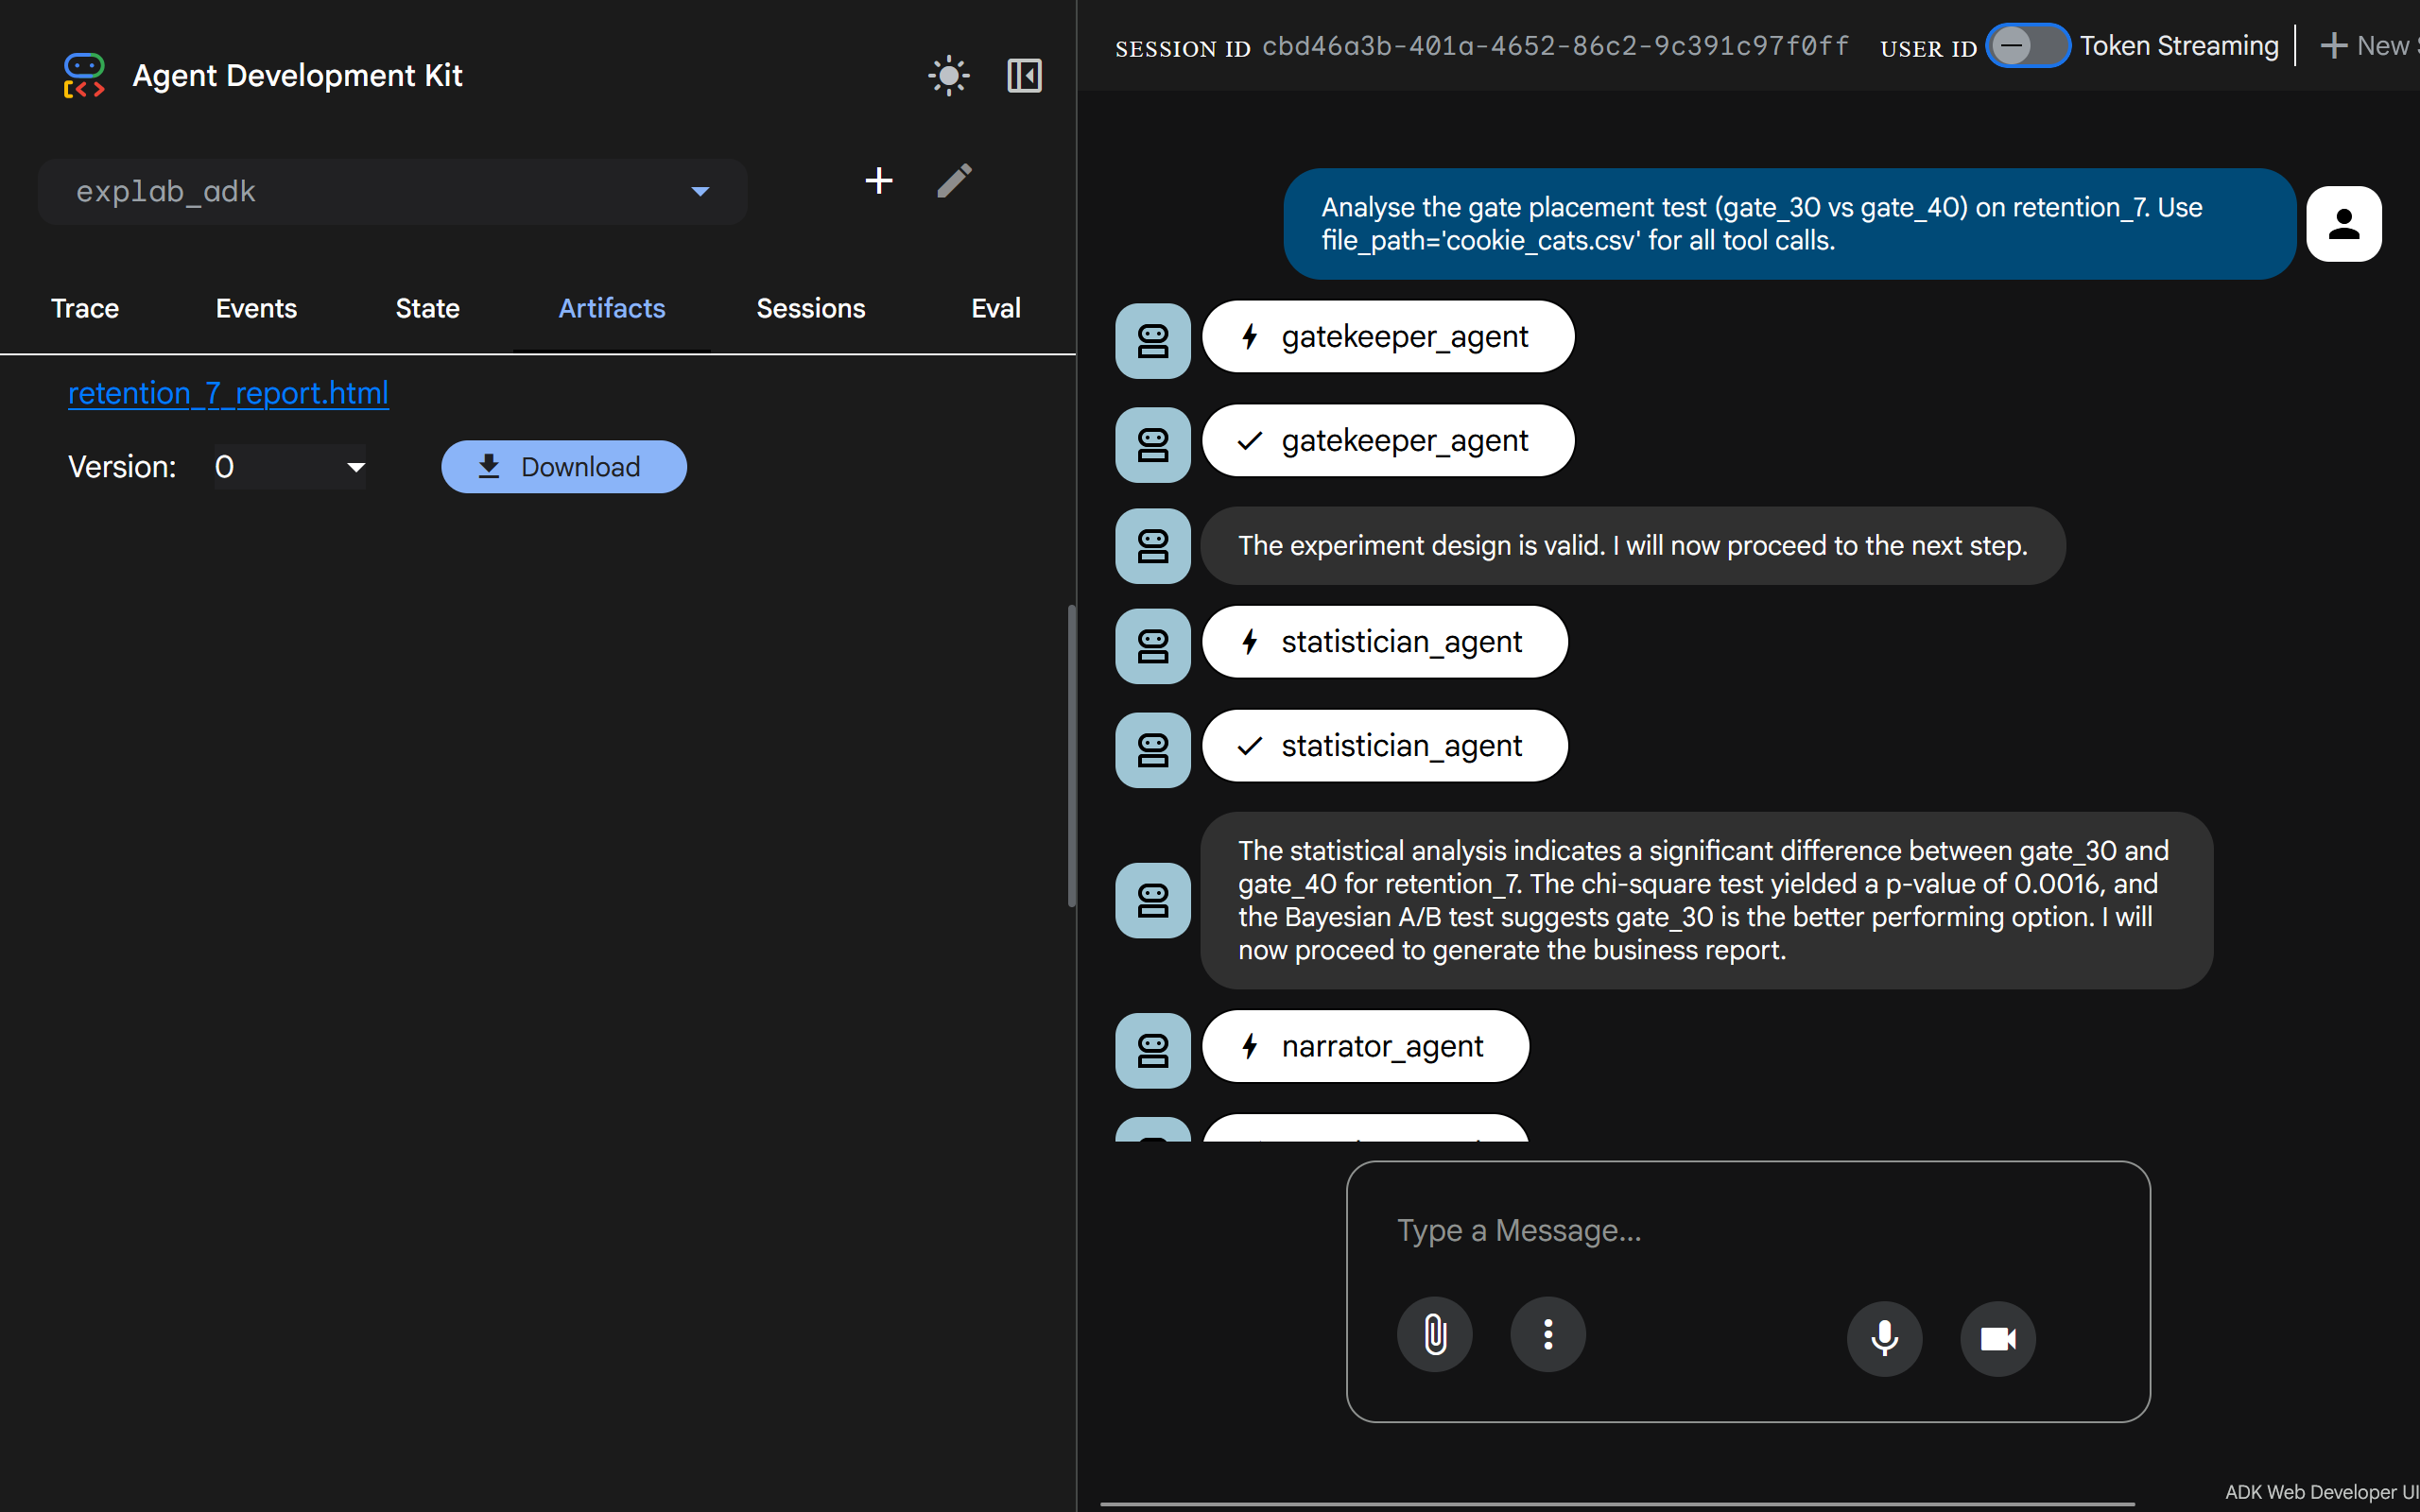
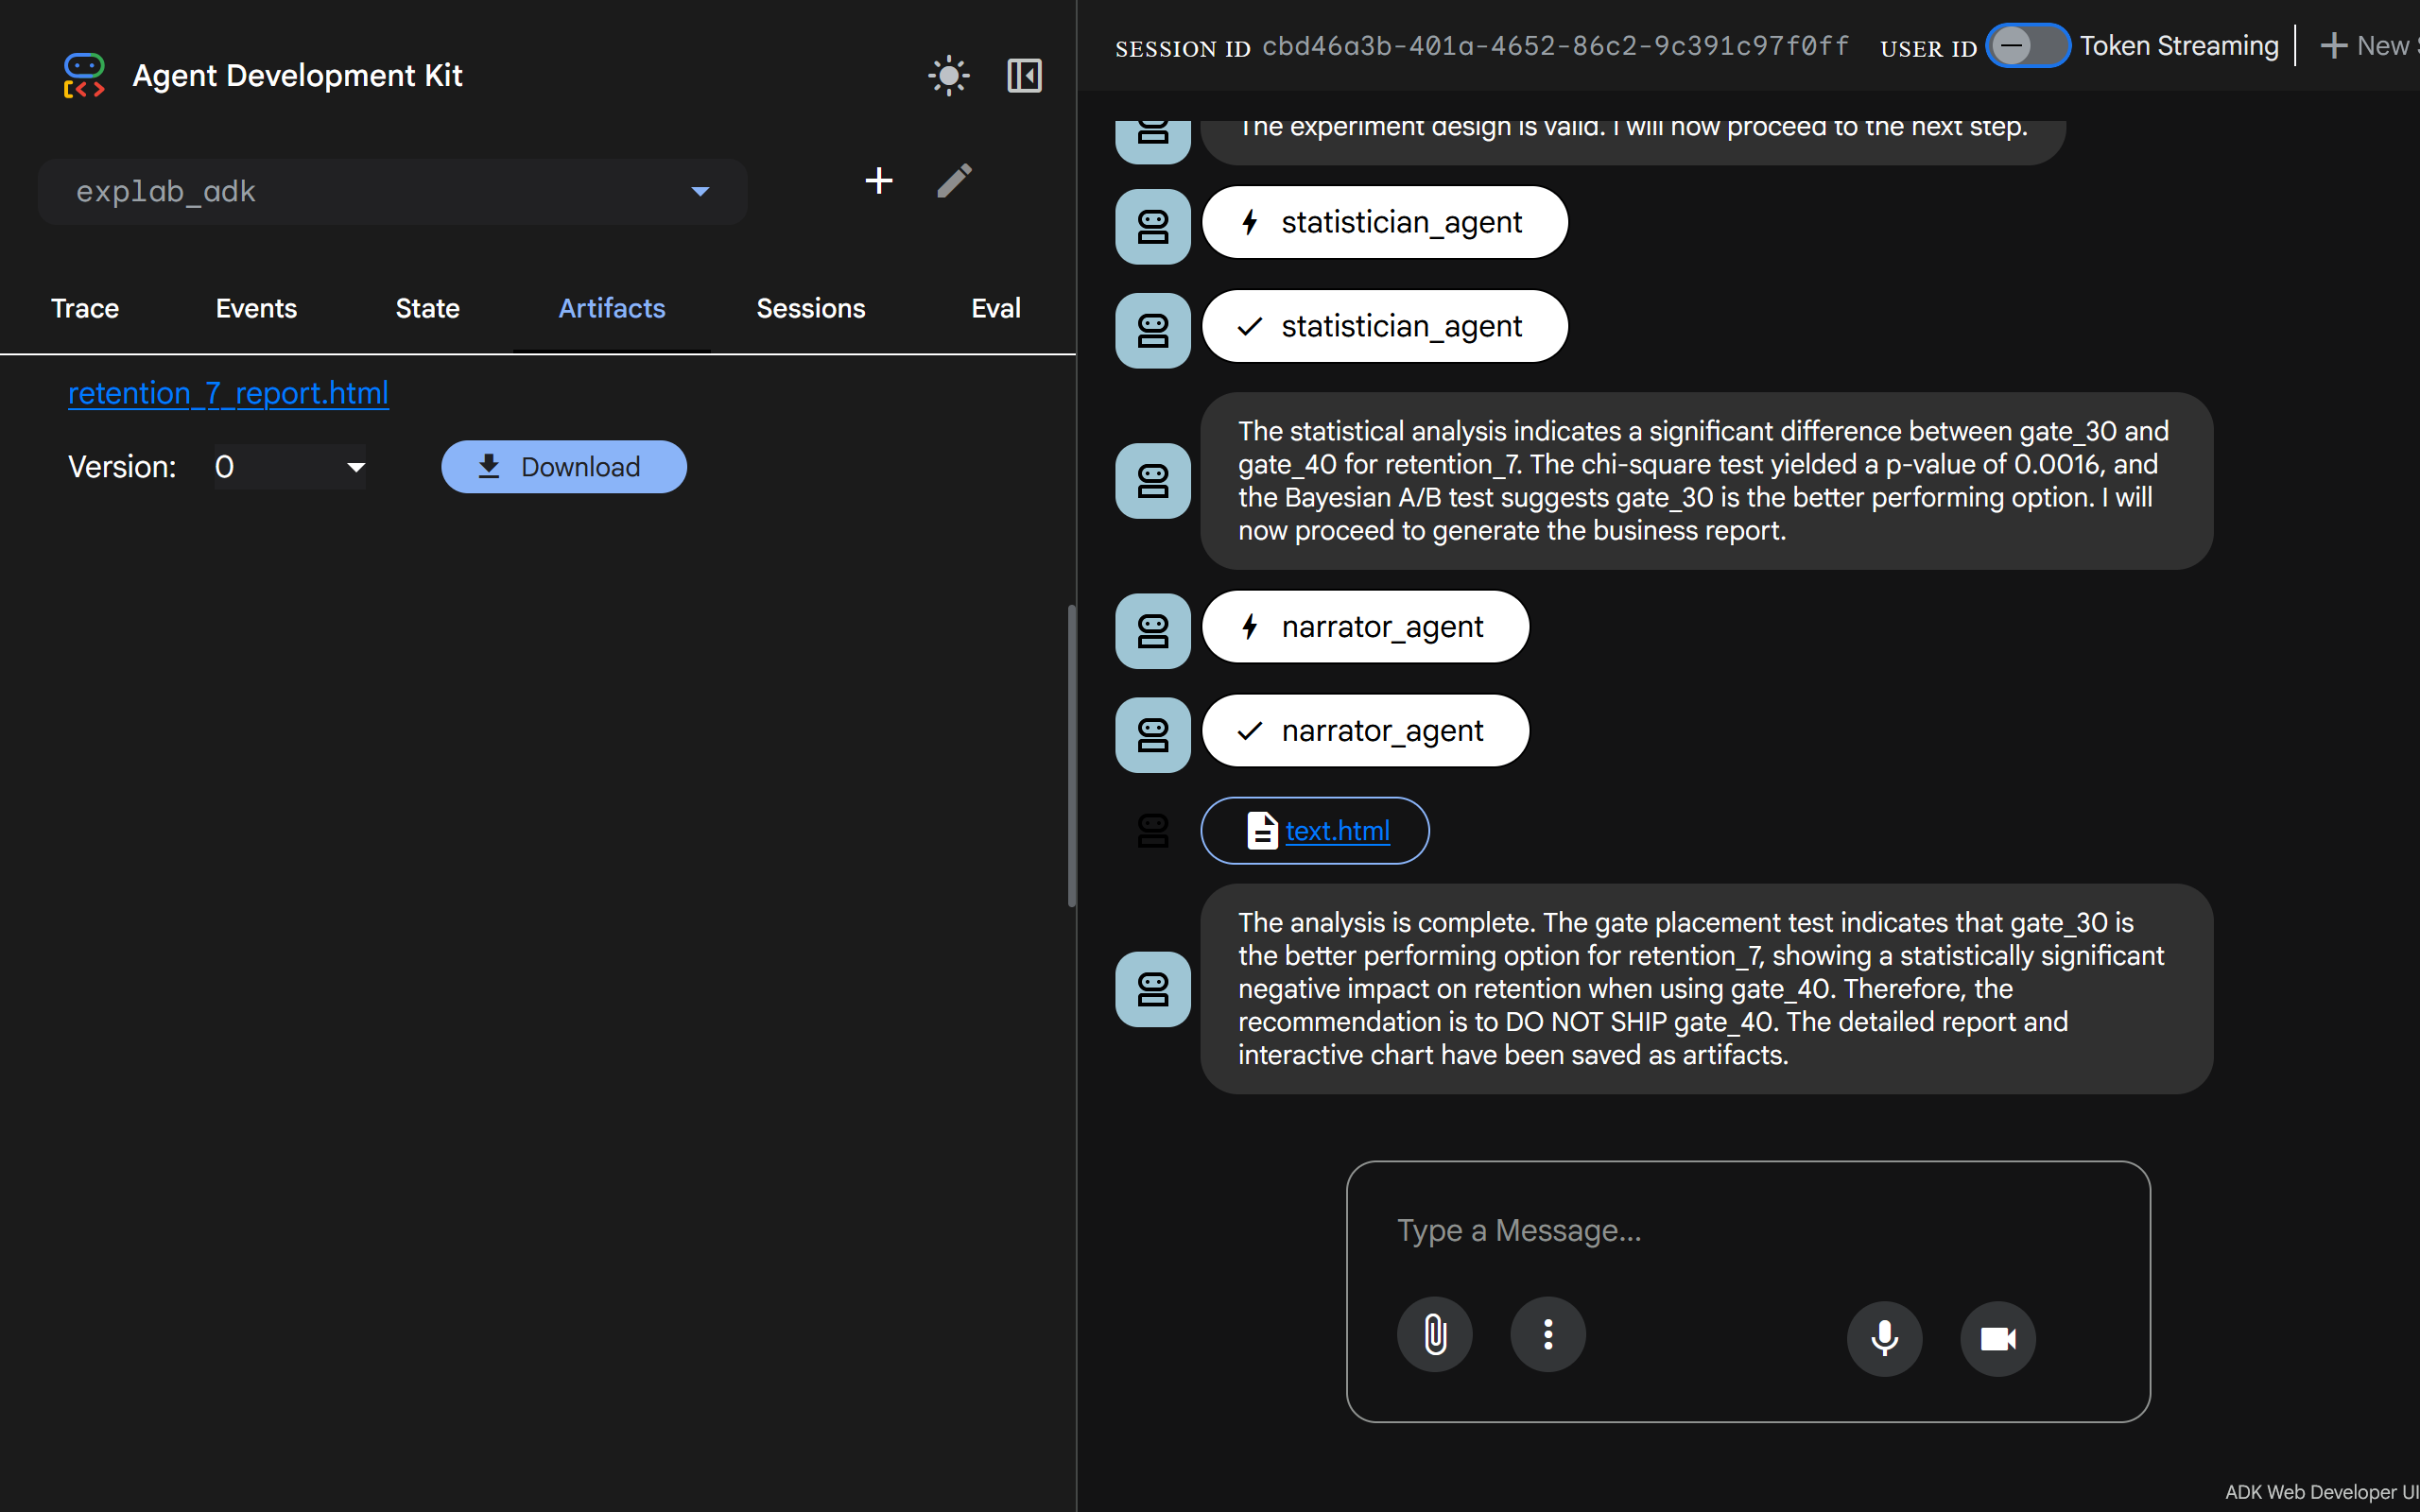

## Main Execution

This cell runs the complete end-to-end pipeline, both the async agentic workflow (`run_complete_analysis`) and the standalone statistical report (`run_cookie_cats_analysis`) and prints a full feature summary and production deployment checklist.

**What to expect in the output:**
1. The ASCII banner confirming all enhancements active
2. The async agent pipeline result for `retention_7` (gatekeeper → statistician → narrator)
3. A feature demonstration summary (multi-format loading, SRM detection, HITL, risk assessment, ADK Artifacts)
4. A production deployment checklist (Parquet conversion, SQLite setup, HITL notifications, eval test cases)
5. The full four-step standalone statistical report with the retention_7 HTML bar chart rendered inline

**Expected runtime:** 1–3 minutes depending on API latency. The async pipeline makes several sequential Gemini API calls. The standalone report runs locally with no API calls.


In [25]:
import asyncio

print("""
╔══════════════════════════════════════════════════════════════╗
║                                                              ║
║   ExpLab AI: Autonomous A/B Experimentation Engine           ║
║                                                              ║
║   ✨ ENHANCEMENTS:                                           ║
║   • Multi-format data (CSV/Parquet/SQLite)                   ║
║   • SRM Detection (Sample Ratio Mismatch)                    ║
║   • Human-in-the-Loop (HITL) workflow                        ║
║   • Risk Assessment section                                  ║
║   • ADK Artifacts visualization                              ║
║                                                              ║
╚══════════════════════════════════════════════════════════════╝
""")

# FIX: run_complete_analysis is now defined above — was a NameError previously
await run_complete_analysis(
    file_path="cookie_cats.csv",
    metric="retention_7"
)

print("\n FEATURE DEMONSTRATIONS")
print("""
✅ Multi-Format Data Loading:
    - CSV: cookie_cats.csv (legacy format)
    - Parquet: Auto-converts CSV → .parquet for 10-100x speedup
    - SQLite: Load from database with SQL queries

✅ SRM Detection:
    - Automatically checks for 50/50 split deviation
    - Uses Chi-square test for rigor
    - Flags CRITICAL if split is 45/55 or worse

✅ Human-in-the-Loop:
    - Pauses if validation fails
    - Requests explicit approval before wasting compute
    - Resumes from exact state after approval

✅ Risk Assessment:
    - Flags: SRM, underpowered tests, small practical effects
    - Risk levels: CRITICAL / WARNING / INFO
    - Overall verdict: SAFE TO SHIP / REQUIRES REVIEW

✅ ADK Artifacts:
    - Bar charts comparing control vs treatment
    - Annotations with p-value, lift %, significance
    - Ready for ADK web UI visualization

📊 Next Steps:
    1. Load your own experiment data (CSV/Parquet/SQLite)
    2. Run: await run_complete_analysis('your_data.parquet')
    3. Review risk assessment in output
    4. Approve/reject via HITL workflow
    5. View results with ADK Artifacts visualization
""")

print("\n" + "-" * 70)
print("PRODUCTION DEPLOYMENT CHECKLIST")
print("-" * 70)
print("""
☐ Convert large CSVs to Parquet:
    → df.to_parquet('data.parquet', compression='snappy')

☐ Set up SQLite for very large datasets:
    → conn = sqlite3.connect('experiments.db')
    → df.to_sql('experiments', conn, if_exists='replace')

☐ Configure HITL approvers:
    → Add authentication for approval requests
    → Set up Slack/email notifications for pauses

☐ Enable ADK Artifacts rendering:
    → Use `adk web` to see chart visualisations
    → Export to PowerPoint/PDF for exec reviews

☐ Set SRM thresholds:
    → Default: 2% deviation triggers WARNING
    → Adjust based on your randomisation quality

☐ Add evaluation test cases:
    → Create explab.evalset.json with SRM scenarios
    → Run: adk eval to catch regressions
""")

print("\n🎉 ExpLab AI is ready for production use!")
print("\n" + "-" * 70)
print("\n REAL DATA ANALYSIS")
print("-" * 70 + "\n")

# FIX: run_cookie_cats_analysis is now defined above — was a NameError previously
run_cookie_cats_analysis("cookie_cats.csv")



╔══════════════════════════════════════════════════════════════╗
║                                                              ║
║   ExpLab AI: Autonomous A/B Experimentation Engine           ║
║                                                              ║
║   ✨ ENHANCEMENTS:                                           ║
║   • Multi-format data (CSV/Parquet/SQLite)                   ║
║   • SRM Detection (Sample Ratio Mismatch)                    ║
║   • Human-in-the-Loop (HITL) workflow                        ║
║   • Risk Assessment section                                  ║
║   • ADK Artifacts visualization                              ║
║                                                              ║
╚══════════════════════════════════════════════════════════════╝

ExpLab AI: Enhanced A/B Testing Engine

 Loading data from cookie_cats.csv...
✓ Loaded 90,189 users
  Format: CSV (converted to cookie_cats.parquet)  |  Load time: 62.71 ms
  Control: 44,700  |  Treatment: 45,489

🔧 Ini

C:\Users\Shrividya\AppData\Local\Temp\ipykernel_25396\536080849.py:5: UserWarning: [EXPERIMENTAL] ResumabilityConfig: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  resumability_config=ResumabilityConfig(is_resumable=True),


[logging_plugin] 🧠 LLM RESPONSE
[logging_plugin]    Agent: explab_supervisor
[logging_plugin]    Content: function_call: gatekeeper_agent
[logging_plugin]    Token Usage - Input: 597, Output: 53
[logging_plugin] 📢 EVENT YIELDED
[logging_plugin]    Event ID: 1cdb6759-b535-4c67-af54-c064f9436887
[logging_plugin]    Author: explab_supervisor
[logging_plugin]    Content: function_call: gatekeeper_agent
[logging_plugin]    Final Response: False
[logging_plugin]    Function Calls: ['gatekeeper_agent']
[logging_plugin] 🔧 TOOL STARTING
[logging_plugin]    Tool Name: gatekeeper_agent
[logging_plugin]    Agent: explab_supervisor
[logging_plugin]    Function Call ID: adk-86bd3188-3a01-49f2-b319-90d486723d05
[logging_plugin]    Arguments: {'request': "Analyse the gate placement test (gate_30 vs gate_40) on retention_7. Use file_path='cookie_cats.csv' for all tool calls."}
[logging_plugin] 🚀 USER MESSAGE RECEIVED
[logging_plugin]    Invocation ID: e-aa629c73-edaa-44c4-b682-7685f33f6a94
[logging_plu


## Results & Conclusion

### Cookie Cats - Summary Findings

| Metric | Control (gate_30) | Treatment (gate_40) | Lift | Significant? |
|:---|:---|:---|:---|:---|
| `retention_1` | ~44.8% | ~44.2% | −0.6% | Borderline |
| `retention_7` | ~19.0% | ~18.2% | −0.8% | **Yes — p < 0.05** |

#### Bayesian Results

| Metric | P(gate_40 > gate_30) | Expected Lift | 95% Credible Interval |
|:---|:---|:---|:---|
| `retention_1` | ~42% | −0.006 | (−0.013, +0.001) |
| `retention_7` | ~1% (control better) | −0.008 | (−0.015, −0.001) |

#### Verdict: **DO NOT SHIP ❌**

Gate 40 significantly hurts 7-day retention. The hedonic adaptation break at level 30 - forcing players to pause before reaching level 31 appears to benefit long-term engagement. Moving the gate to level 40 removes this break too late, allowing players to burn out before encountering it.

The Bayesian analysis corroborates the frequentist result, there is a very high posterior probability (~99%) that gate_30 outperforms gate_40 on 7-day retention, providing decision confidence beyond the p < 0.05 threshold alone.


### GenAI & Agentic Capabilities Summary

| Feature | ADK Component | How Used |
|:---|:---|:---|
| Multi-Agent Orchestration | `LlmAgent` + `AgentTool` | Supervisor delegates to three specialist agents; each has a focused role and isolated tool set |
| Human-in-the-Loop | `ResumabilityConfig(is_resumable=True)` | Pipeline pauses on validation failure; resumes only after explicit human approval |
| Session & State Management | `InMemorySessionService`, `output_key` | Agent outputs stored in session state and passed as context to downstream agents |
| Long-Term Memory | `InMemoryMemoryService` | Completed sessions committed to memory; patterns persist across analysis runs |
| ADK Artifacts | `tool_context.save_artifact()` | HTML bar chart saved as `text/html` artifact; renders in ADK Web UI Artifacts tab |
| Observability | `LoggingPlugin` | All agent events, tool calls, and responses captured for audit trail and debugging |
| Retry & Resilience | `types.HttpRetryOptions` | Exponential backoff on rate limit and server errors applied to all agents |
| Web UI Deployment | `google.adk.cli web` | Agent package auto-generated as `explab_adk/agent.py` for interactive chat interface |



###  Known Limitations

**1. In-Memory Session Storage** - Sessions are lost on process restart. Production HITL workflows requiring hours of pause time need persistent session storage (e.g., Cloud Storage or a database backend).

**2. Simulated HITL in Notebook** - `run_complete_analysis` auto-approves in demo mode for single-execution readability. Deploy via `adk web` or Vertex AI Agent Engine for genuine human approval workflows.

**3. Dataset-Specific Schema** - Tool functions currently expect the Cookie Cats column names (`version`, `gate_30`, `gate_40`, `retention_1`, `retention_7`). Adapting to other datasets requires updating column references or adding a schema mapping layer.

**4. Binary-Only Bayesian Model** - The Beta-Binomial conjugate model is valid only for binary metrics. Continuous metrics (revenue, session length) require a different Bayesian model.
